<a href="https://colab.research.google.com/github/saleem7369/Fuel/blob/main/Anticancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Basic libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Plot style
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

In [ ]:
file_path = "/content/drive/MyDrive/Colab Notebooks/Dr. Khan/Anticancer/Azo_Schiff_Anticancer_Synthetic_Dataset_350 (1).xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (350, 15)


In [ ]:
df.head()

,Compound ID,Ligand,Metal,Cell line,IC50_uM,DOI,HOMO,LUMO,Gap,Dipole,Hardness,Softness,LogP,TPSA,MW
0,ASB-001,Acetylacetone,Ni,MCF-7,77.28,10.1000/synth.001,-6.742,-2.540,4.202,3.05,2.101,0.476,4.32,104.44,672.56
1,ASB-002,Acetylacetone,Cu,HepG2,78.38,10.1000/synth.002,-6.585,-2.642,3.943,6.20,1.972,0.507,3.34,108.76,588.58
2,ASB-003,Naphthaldehyde,Pd,MCF-7,128.23,10.1000/synth.003,-4.938,-3.184,1.754,7.89,0.877,1.140,4.11,67.43,348.41
3,ASB-004,Acetylacetone,Ni,MCF-7,76.53,10.1000/synth.004,-5.926,-2.338,3.588,4.05,1.794,0.557,1.68,34.78,482.15
4,ASB-005,Naphthaldehyde,Pd,MCF-7,84.41,10.1000/synth.005,-4.892,-1.716,3.176,8.35,1.588,0.630,3.43,107.50,300.16


In [ ]:
print("Dataset Columns:")
for col in df.columns:
    print("-", col)

Dataset Columns:
- Compound ID
- Ligand
- Metal
- Cell line
- IC50_uM
- DOI
- HOMO
- LUMO
- Gap
- Dipole
- Hardness
- Softness
- LogP
- TPSA
- MW


In [ ]:
expected_columns = [
    "Compound ID", "Ligand", "Metal", "Cell line", "IC50_uM", "DOI",
    "HOMO", "LUMO", "Gap", "Dipole", "Hardness", "Softness",
    "LogP", "TPSA", "MW"
]

print("Missing expected columns:")
print(set(expected_columns) - set(df.columns))

print("\nExtra columns:")
print(set(df.columns) - set(expected_columns))

Missing expected columns:
set()

Extra columns:
set()


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Compound ID  350 non-null    object 
 1   Ligand       350 non-null    object 
 2   Metal        350 non-null    object 
 3   Cell line    350 non-null    object 
 4   IC50_uM      350 non-null    float64
 5   DOI          350 non-null    object 
 6   HOMO         350 non-null    float64
 7   LUMO         350 non-null    float64
 8   Gap          350 non-null    float64
 9   Dipole       350 non-null    float64
 10  Hardness     350 non-null    float64
 11  Softness     350 non-null    float64
 12  LogP         350 non-null    float64
 13  TPSA         350 non-null    float64
 14  MW           350 non-null    float64
dtypes: float64(10), object(5)
memory usage: 41.1+ KB


In [ ]:
missing_values = df.isnull().sum().sort_values(ascending=False)

missing_values

,0
Compound ID,0
Ligand,0
Metal,0
Cell line,0
IC50_uM,0
DOI,0
HOMO,0
LUMO,0
Gap,0
Dipole,0


In [ ]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


Dataset Distribution

In [ ]:
metal_counts = df["Metal"].value_counts().reset_index()
metal_counts.columns = ["Metal", "Number of Compounds"]

metal_counts

,Metal,Number of Compounds
0,Ni,48
1,Zn,48
2,Cu,47
3,Ru,45
4,Co,43
5,Pd,42
6,Pt,41
7,Fe,36


/tmp/ipykernel_709/595573731.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


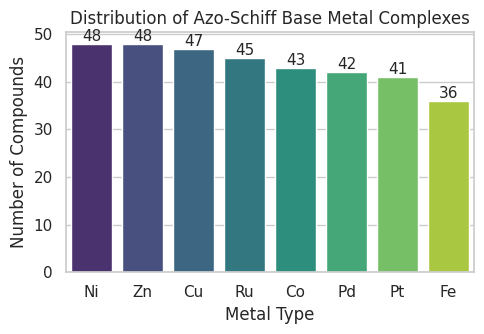

In [ ]:
plt.figure(figsize=(5, 3.5))
ax = sns.barplot(
    data=metal_counts,
    x="Metal",
    y="Number of Compounds",
    palette="viridis"
)

plt.title("Distribution of Azo-Schiff Base Metal Complexes")
plt.xlabel("Metal Type")
plt.ylabel("Number of Compounds")

for container in ax.containers:
    ax.bar_label(container, fontsize=11)

plt.tight_layout()
plt.show()

Ligand Distribution

In [ ]:
ligand_counts = df["Ligand"].value_counts().reset_index()
ligand_counts.columns = ["Ligand", "Number of Compounds"]

ligand_counts

,Ligand,Number of Compounds
0,Acetylacetone,69
1,Vanillin,63
2,Salicylaldehyde,56
3,Anisaldehyde,55
4,2-Hydroxybenzaldehyde,54
5,Naphthaldehyde,53


/tmp/ipykernel_709/4035455559.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


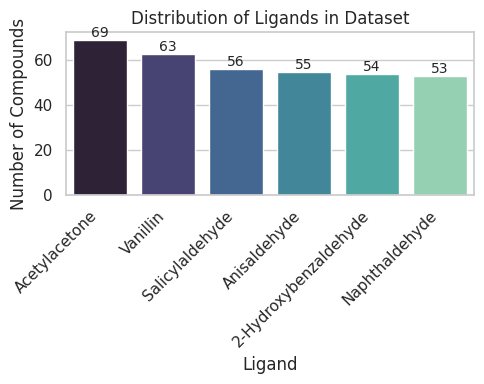

In [ ]:
plt.figure(figsize=(5, 4))
ax = sns.barplot(
    data=ligand_counts,
    x="Ligand",
    y="Number of Compounds",
    palette="mako"
)

plt.title("Distribution of Ligands in Dataset")
plt.xlabel("Ligand")
plt.ylabel("Number of Compounds")
plt.xticks(rotation=45, ha='right')

for container in ax.containers:
    ax.bar_label(container, fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
cell_counts = df["Cell line"].value_counts().reset_index()
cell_counts.columns = ["Cell line", "Number of Compounds"]

cell_counts

,Cell line,Number of Compounds
0,A549,54
1,MDA-MB-231,54
2,HepG2,51
3,PC-3,50
4,MCF-7,49
5,HCT116,49
6,HeLa,43


/tmp/ipykernel_709/2048891133.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


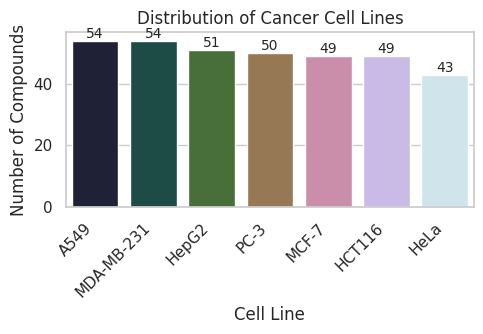

In [ ]:
plt.figure(figsize=(5, 3.5))
ax = sns.barplot(
    data=cell_counts,
    x="Cell line",
    y="Number of Compounds",
    palette="cubehelix"
)

plt.title("Distribution of Cancer Cell Lines")
plt.xlabel("Cell Line")
plt.ylabel("Number of Compounds")
plt.xticks(rotation=45, ha='right')

for container in ax.containers:
    ax.bar_label(container, fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
target = "IC50_uM"

print("IC50 Summary:")
print(df[target].describe())

IC50 Summary:
count    350.000000
mean      86.616229
std       19.380916
min       39.060000
25%       74.557500
50%       86.900000
75%       99.730000
max      135.800000
Name: IC50_uM, dtype: float64


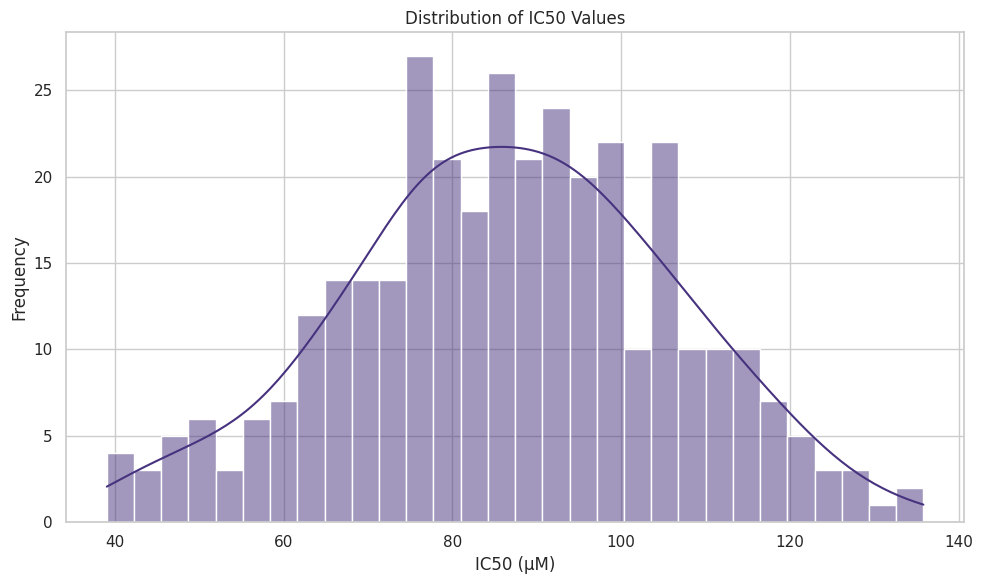

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df[target], kde=True, bins=30)
plt.title("Distribution of IC50 Values")
plt.xlabel("IC50 (µM)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

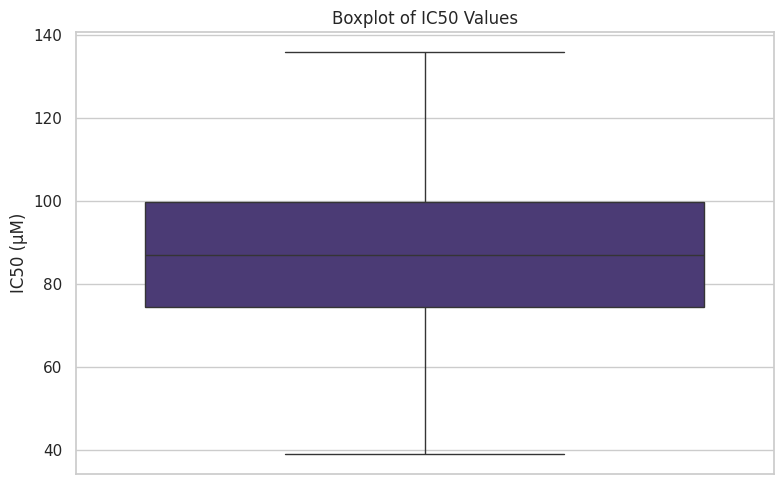

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df[target])
plt.title("Boxplot of IC50 Values")
plt.ylabel("IC50 (µM)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_709/2337568675.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Metal", y="IC50_uM", palette="Set3")


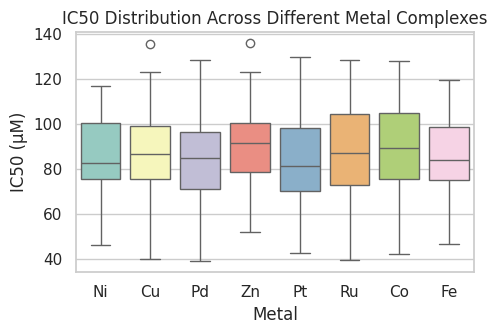

In [ ]:
plt.figure(figsize=(5, 3.5))
sns.boxplot(data=df, x="Metal", y="IC50_uM", palette="Set3")
plt.title("IC50 Distribution Across Different Metal Complexes")
plt.xlabel("Metal")
plt.ylabel("IC50 (µM)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_709/3220894730.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="Metal", y="IC50_uM", palette="viridis", inner="box")


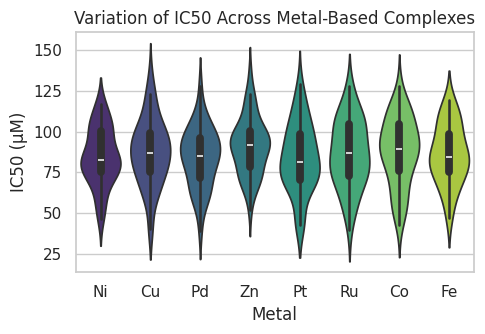

In [ ]:
plt.figure(figsize=(5, 3.5))
sns.violinplot(data=df, x="Metal", y="IC50_uM", palette="viridis", inner="box")
plt.title("Variation of IC50 Across Metal-Based Complexes")
plt.xlabel("Metal")
plt.ylabel("IC50 (µM)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_709/2105370157.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Cell line", y="IC50_uM", palette="coolwarm")


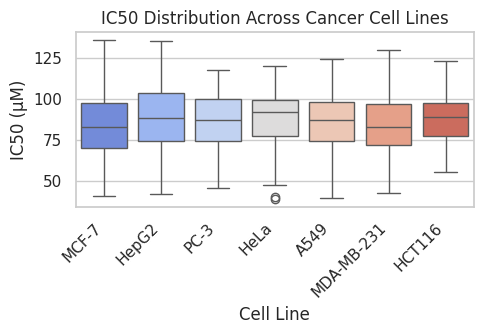

In [ ]:
plt.figure(figsize=(5, 3.5))
sns.boxplot(data=df, x="Cell line", y="IC50_uM", palette="coolwarm")
plt.title("IC50 Distribution Across Cancer Cell Lines")
plt.xlabel("Cell Line")
plt.ylabel("IC50 (µM)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
numeric_cols = [
    "HOMO", "LUMO", "Gap", "Dipole", "Hardness", "Softness",
    "LogP", "TPSA", "MW", "IC50_uM"
]

df[numeric_cols].head()

,HOMO,LUMO,Gap,Dipole,Hardness,Softness,LogP,TPSA,MW,IC50_uM
0,-6.742,-2.540,4.202,3.05,2.101,0.476,4.32,104.44,672.56,77.28
1,-6.585,-2.642,3.943,6.20,1.972,0.507,3.34,108.76,588.58,78.38
2,-4.938,-3.184,1.754,7.89,0.877,1.140,4.11,67.43,348.41,128.23
3,-5.926,-2.338,3.588,4.05,1.794,0.557,1.68,34.78,482.15,76.53
4,-4.892,-1.716,3.176,8.35,1.588,0.630,3.43,107.50,300.16,84.41


In [ ]:
descriptor_summary = df[numeric_cols].describe().T
descriptor_summary

,count,mean,std,min,25%,50%,75%,max
HOMO,350.0,-5.592837,0.661009,-6.788,-6.14000,-5.6165,-4.98775,-4.500
LUMO,350.0,-2.012389,0.669643,-3.184,-2.58725,-1.9765,-1.40225,-0.813
Gap,350.0,3.580449,0.940844,1.512,2.91725,3.5220,4.26700,5.767
Dipole,350.0,5.401600,2.290292,1.210,3.60250,5.3600,7.25750,9.500
Hardness,350.0,1.790223,0.470399,0.756,1.45825,1.7610,2.13350,2.884
Softness,350.0,0.604194,0.185403,0.347,0.46900,0.5680,0.68575,1.323
LogP,350.0,2.938829,1.632462,0.230,1.56000,2.8500,4.32000,5.800
TPSA,350.0,82.590514,30.839705,30.060,55.80000,81.4450,106.86500,139.570
MW,350.0,506.476000,127.314963,280.560,397.06000,512.0600,612.12000,719.700
IC50_uM,350.0,86.616229,19.380916,39.060,74.55750,86.9000,99.73000,135.800


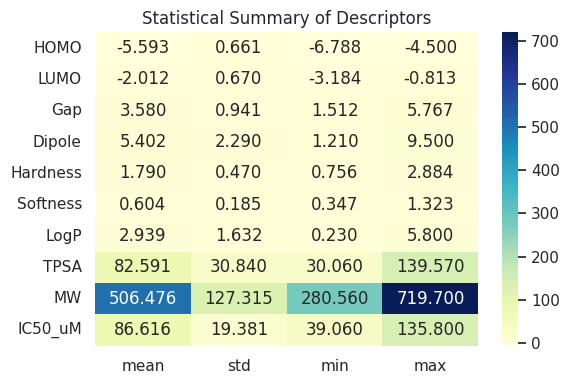

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(descriptor_summary[["mean", "std", "min", "max"]], annot=True, cmap="YlGnBu", fmt=".3f")
plt.title("Statistical Summary of Descriptors")
plt.tight_layout()
plt.show()

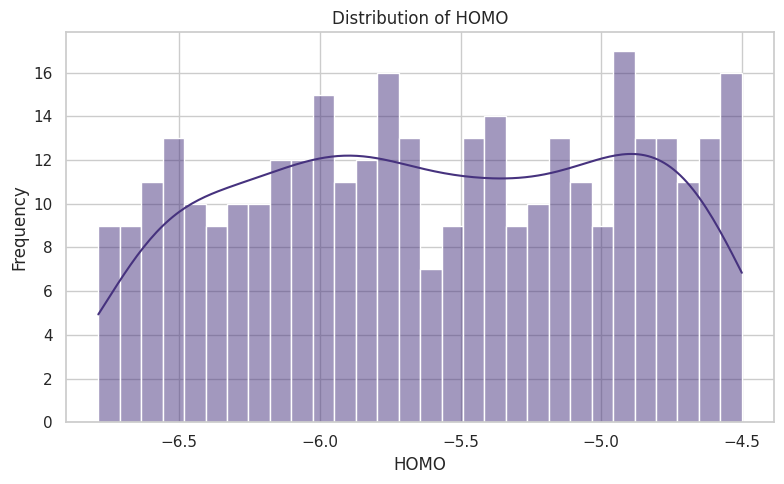

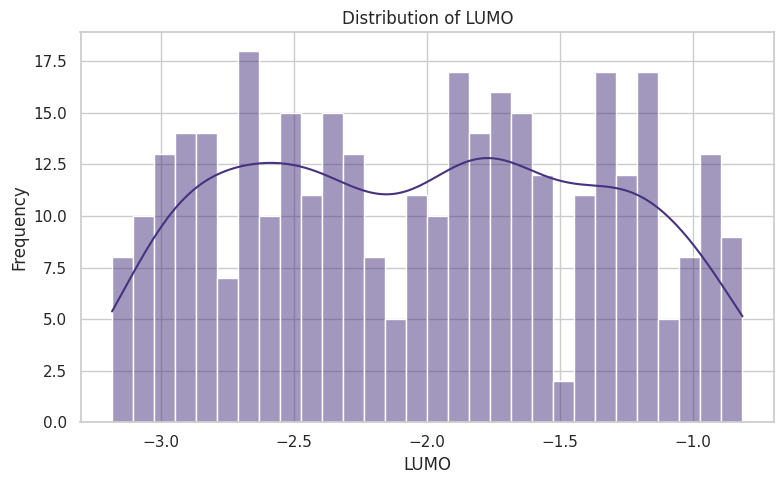

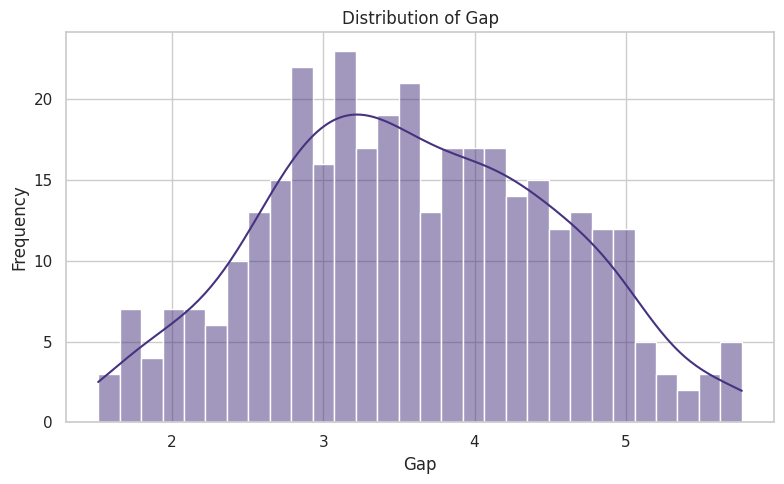

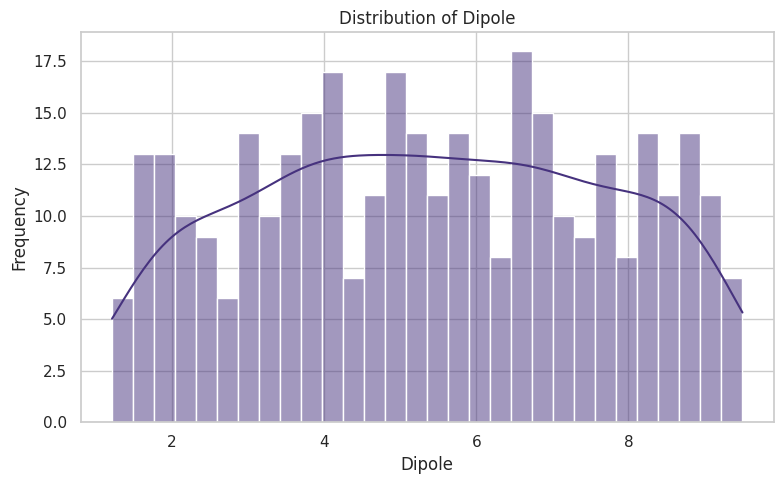

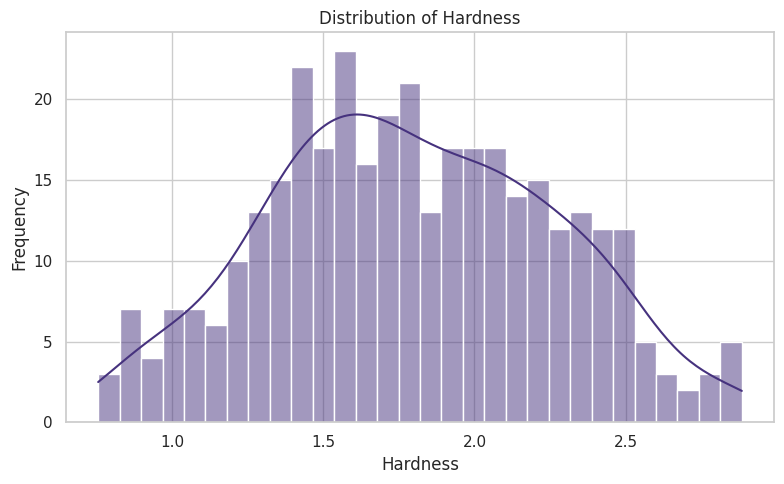

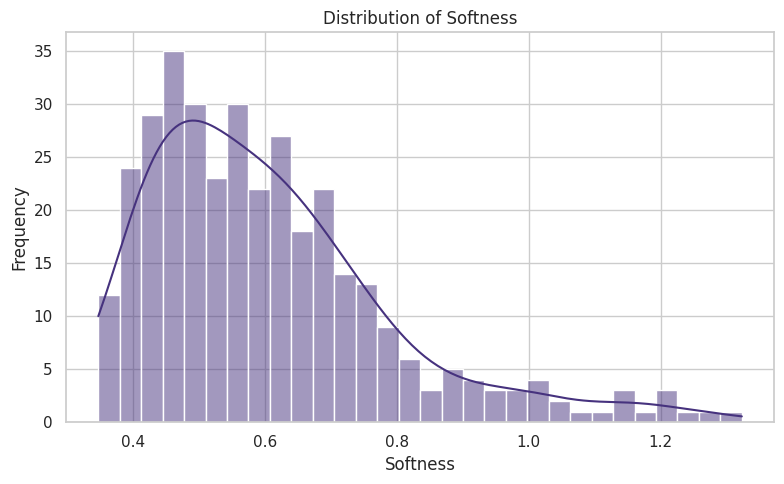

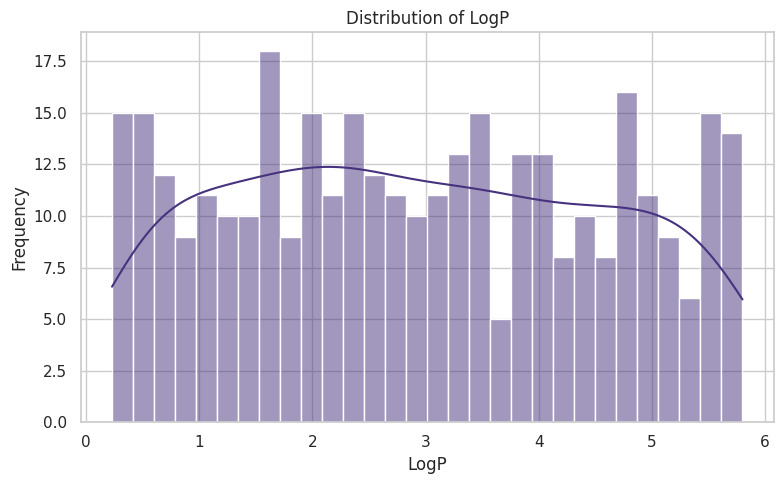

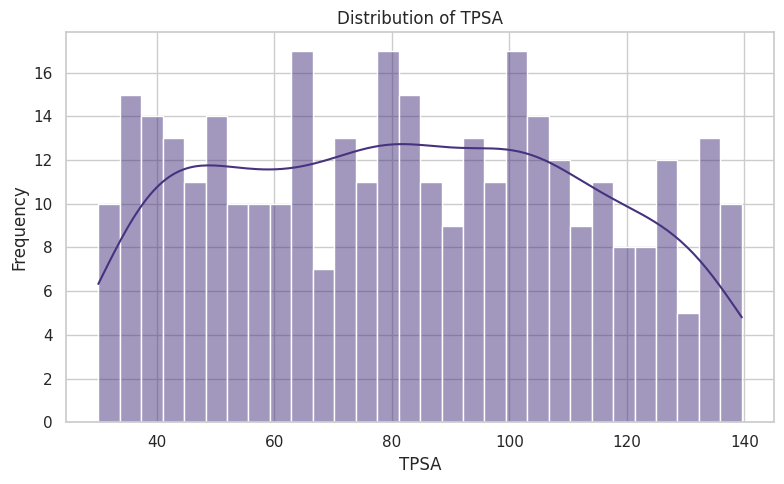

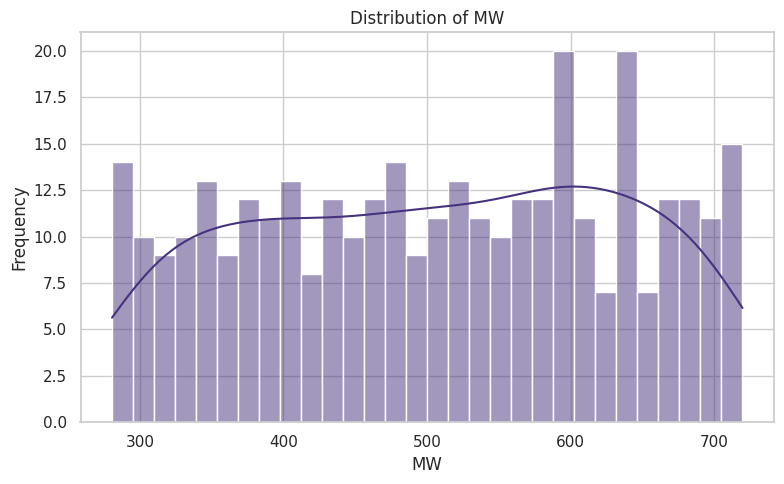

In [ ]:
descriptor_cols = [
    "HOMO", "LUMO", "Gap", "Dipole", "Hardness", "Softness",
    "LogP", "TPSA", "MW"
]

for col in descriptor_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [ ]:
corr_matrix = df[numeric_cols].corr()

corr_matrix

,HOMO,LUMO,Gap,Dipole,Hardness,Softness,LogP,TPSA,MW,IC50_uM
HOMO,1.000000,0.000189,-0.702436,0.020350,-0.702460,0.658138,-0.050090,0.001592,-0.004877,0.589450
LUMO,0.000189,1.000000,0.711614,-0.023105,0.711590,-0.668881,0.062210,-0.067916,0.005546,-0.615175
Gap,-0.702436,0.711614,1.000000,-0.030742,1.000000,-0.938462,0.079470,-0.049457,0.007374,-0.851980
Dipole,0.020350,-0.023105,-0.030742,1.000000,-0.030756,0.068639,-0.068051,0.084345,0.098068,-0.259620
Hardness,-0.702460,0.711590,1.000000,-0.030756,1.000000,-0.938440,0.079490,-0.049540,0.007390,-0.851978
Softness,0.658138,-0.668881,-0.938462,0.068639,-0.938440,1.000000,-0.035241,0.060380,0.006104,0.796903
LogP,-0.050090,0.062210,0.079470,-0.068051,0.079490,-0.035241,1.000000,-0.038872,-0.026444,0.277492
TPSA,0.001592,-0.067916,-0.049457,0.084345,-0.049540,0.060380,-0.038872,1.000000,0.043982,0.007222
MW,-0.004877,0.005546,0.007374,0.098068,0.007390,0.006104,-0.026444,0.043982,1.000000,-0.038085
IC50_uM,0.589450,-0.615175,-0.851980,-0.259620,-0.851978,0.796903,0.277492,0.007222,-0.038085,1.000000


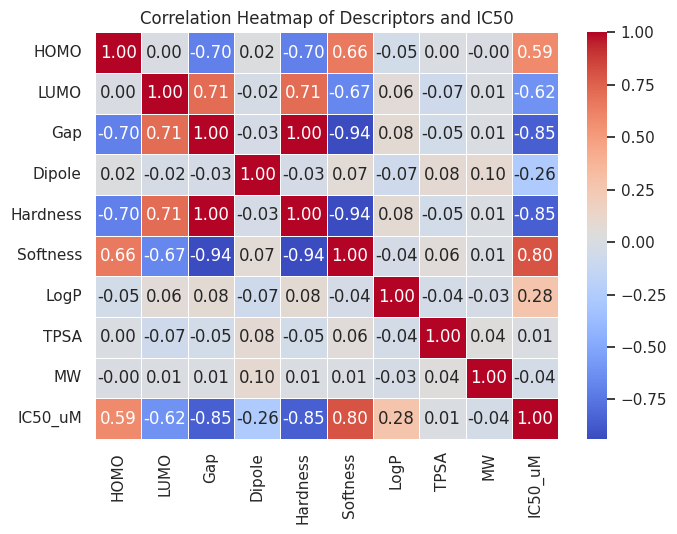

In [ ]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Descriptors and IC50")
plt.tight_layout()
plt.show()

In [ ]:
ic50_corr = corr_matrix["IC50_uM"].drop("IC50_uM").sort_values(ascending=False)

ic50_corr

,IC50_uM
Softness,0.796903
HOMO,0.589450
LogP,0.277492
TPSA,0.007222
MW,-0.038085
Dipole,-0.259620
LUMO,-0.615175
Hardness,-0.851978
Gap,-0.851980


/tmp/ipykernel_709/192588848.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


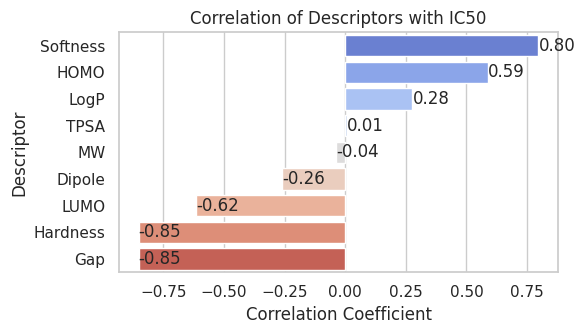

In [ ]:
plt.figure(figsize=(6, 3.5))
ax = sns.barplot(
    x=ic50_corr.values,
    y=ic50_corr.index,
    palette="coolwarm"
)

plt.title("Correlation of Descriptors with IC50")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Descriptor")

for i, v in enumerate(ic50_corr.values):
    ax.text(v, i, f"{v:.2f}", va='center')

plt.tight_layout()
plt.show()

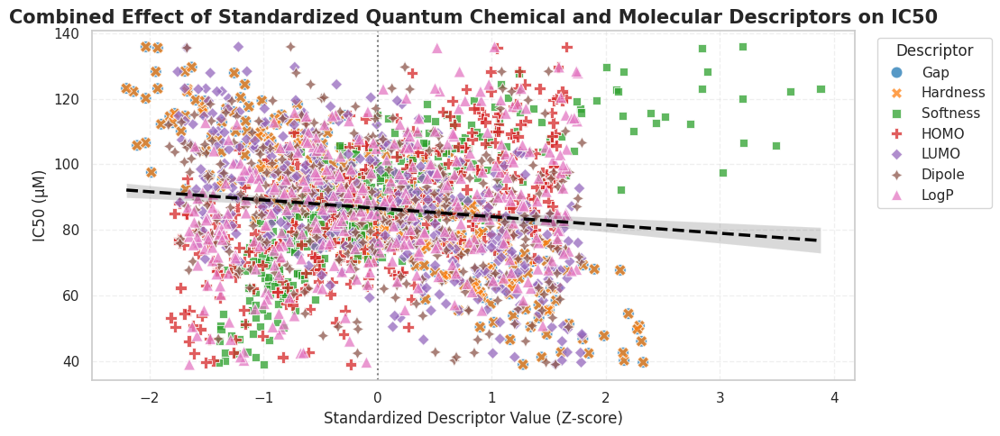

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

important_features = ["Gap", "Hardness", "Softness", "HOMO", "LUMO", "Dipole", "LogP"]

# Copy original data
plot_df = df[important_features + ["IC50_uM", "Metal"]].copy()

# Standardize descriptor values for fair comparison in one plot
scaler = StandardScaler()
plot_df[important_features] = scaler.fit_transform(plot_df[important_features])

# Convert wide format into long format
df_long = plot_df.melt(
    id_vars=["IC50_uM", "Metal"],
    value_vars=important_features,
    var_name="Descriptor",
    value_name="Standardized_Descriptor_Value"
)

plt.figure(figsize=(11, 5))

sns.scatterplot(
    data=df_long,
    x="Standardized_Descriptor_Value",
    y="IC50_uM",
    hue="Descriptor",
    style="Descriptor",
    palette="tab10",
    s=85,
    alpha=0.75
)

sns.regplot(
    data=df_long,
    x="Standardized_Descriptor_Value",
    y="IC50_uM",
    scatter=False,
    color="black",
    line_kws={"linewidth": 2.5, "linestyle": "--"}
)

plt.axvline(0, color="gray", linestyle=":", linewidth=1.5)

plt.title(
    "Combined Effect of Standardized Quantum Chemical and Molecular Descriptors on IC50",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Standardized Descriptor Value (Z-score)")
plt.ylabel("IC50 (µM)")

plt.legend(
    title="Descriptor",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True
)

plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

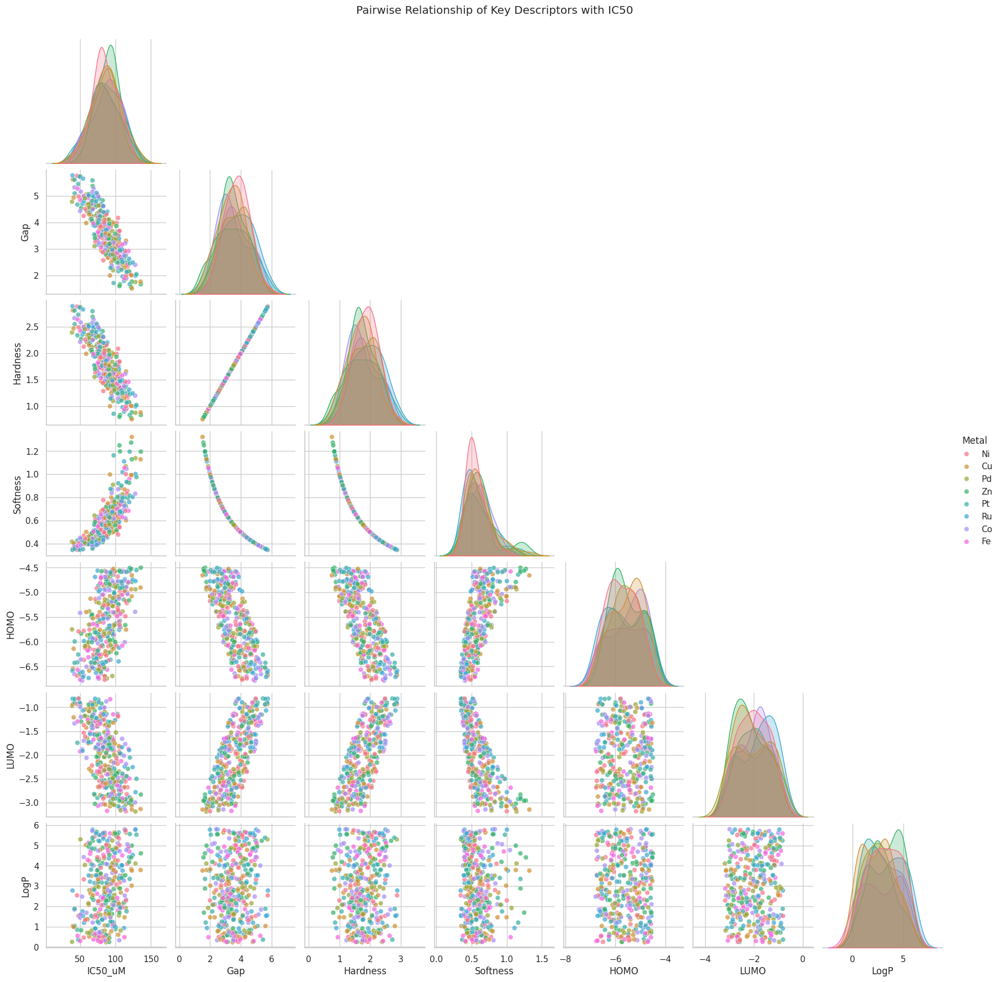

In [ ]:
selected_pairplot_cols = ["IC50_uM", "Gap", "Hardness", "Softness", "HOMO", "LUMO", "LogP", "Metal"]

sns.pairplot(
    df[selected_pairplot_cols],
    hue="Metal",
    diag_kind="kde",
    corner=True,
    plot_kws={"alpha": 0.7, "s": 40}
)

plt.suptitle("Pairwise Relationship of Key Descriptors with IC50", y=1.02)
plt.show()

In [ ]:
supervisor_requirements = pd.DataFrame({
    "Metal_Group": ["Cu", "Ni", "Co", "Zn", "Pd/Pt/Ru/Fe/Others"],
    "Required_Min": [70, 40, 40, 30, 70],
    "Required_Max": [90, 60, 60, 50, 120]
})

actual_counts = {
    "Cu": df[df["Metal"] == "Cu"].shape[0],
    "Ni": df[df["Metal"] == "Ni"].shape[0],
    "Co": df[df["Metal"] == "Co"].shape[0],
    "Zn": df[df["Metal"] == "Zn"].shape[0],
    "Pd/Pt/Ru/Fe/Others": df[df["Metal"].isin(["Pd", "Pt", "Ru", "Fe"])].shape[0]
}

supervisor_requirements["Actual_Count"] = supervisor_requirements["Metal_Group"].map(actual_counts)

supervisor_requirements["Status"] = supervisor_requirements.apply(
    lambda row: "Within Range" if row["Required_Min"] <= row["Actual_Count"] <= row["Required_Max"] else "Out of Range",
    axis=1
)

supervisor_requirements

,Metal_Group,Required_Min,Required_Max,Actual_Count,Status
0,Cu,70,90,47,Out of Range
1,Ni,40,60,48,Within Range
2,Co,40,60,43,Within Range
3,Zn,30,50,48,Within Range
4,Pd/Pt/Ru/Fe/Others,70,120,164,Out of Range


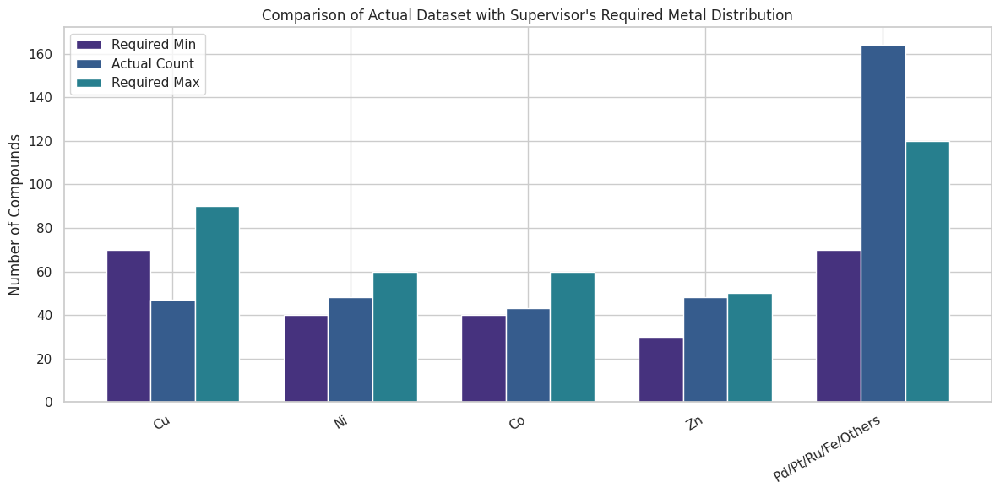

In [ ]:
plt.figure(figsize=(12, 6))

x = np.arange(len(supervisor_requirements))
width = 0.25

plt.bar(x - width, supervisor_requirements["Required_Min"], width, label="Required Min")
plt.bar(x, supervisor_requirements["Actual_Count"], width, label="Actual Count")
plt.bar(x + width, supervisor_requirements["Required_Max"], width, label="Required Max")

plt.xticks(x, supervisor_requirements["Metal_Group"], rotation=30, ha='right')
plt.ylabel("Number of Compounds")
plt.title("Comparison of Actual Dataset with Supervisor's Required Metal Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
df["Ionization_Potential"] = -df["HOMO"]
df["Electron_Affinity"] = -df["LUMO"]
df["Electronegativity"] = (df["Ionization_Potential"] + df["Electron_Affinity"]) / 2
df["Chemical_Potential"] = -df["Electronegativity"]
df["Electrophilicity_Index"] = (df["Chemical_Potential"] ** 2) / (2 * df["Hardness"])

df.head()

,Compound ID,Ligand,Metal,Cell line,IC50_uM,DOI,HOMO,LUMO,Gap,Dipole,Hardness,Softness,LogP,TPSA,MW,Ionization_Potential,Electron_Affinity,Electronegativity,Chemical_Potential,Electrophilicity_Index
0,ASB-001,Acetylacetone,Ni,MCF-7,77.28,10.1000/synth.001,-6.742,-2.540,4.202,3.05,2.101,0.476,4.32,104.44,672.56,6.742,2.540,4.6410,-4.6410,5.125864
1,ASB-002,Acetylacetone,Cu,HepG2,78.38,10.1000/synth.002,-6.585,-2.642,3.943,6.20,1.972,0.507,3.34,108.76,588.58,6.585,2.642,4.6135,-4.6135,5.396649
2,ASB-003,Naphthaldehyde,Pd,MCF-7,128.23,10.1000/synth.003,-4.938,-3.184,1.754,7.89,0.877,1.140,4.11,67.43,348.41,4.938,3.184,4.0610,-4.0610,9.402349
3,ASB-004,Acetylacetone,Ni,MCF-7,76.53,10.1000/synth.004,-5.926,-2.338,3.588,4.05,1.794,0.557,1.68,34.78,482.15,5.926,2.338,4.1320,-4.1320,4.758479
4,ASB-005,Naphthaldehyde,Pd,MCF-7,84.41,10.1000/synth.005,-4.892,-1.716,3.176,8.35,1.588,0.630,3.43,107.50,300.16,4.892,1.716,3.3040,-3.3040,3.437159


In [ ]:
derived_cols = [
    "Ionization_Potential",
    "Electron_Affinity",
    "Electronegativity",
    "Chemical_Potential",
    "Electrophilicity_Index"
]

df[derived_cols].describe()

,Ionization_Potential,Electron_Affinity,Electronegativity,Chemical_Potential,Electrophilicity_Index
count,350.000000,350.000000,350.000000,350.000000,350.000000
mean,5.592837,2.012389,3.802613,-3.802613,4.436053
std,0.661009,0.669643,0.470511,0.470511,1.719302
min,4.500000,0.813000,2.728000,-4.889000,1.957689
25%,4.987750,1.402250,3.439625,-4.167500,2.997766
50%,5.616500,1.976500,3.780750,-3.780750,4.008373
75%,6.140000,2.587250,4.167500,-3.439625,5.548961
max,6.788000,3.184000,4.889000,-2.728000,10.054366


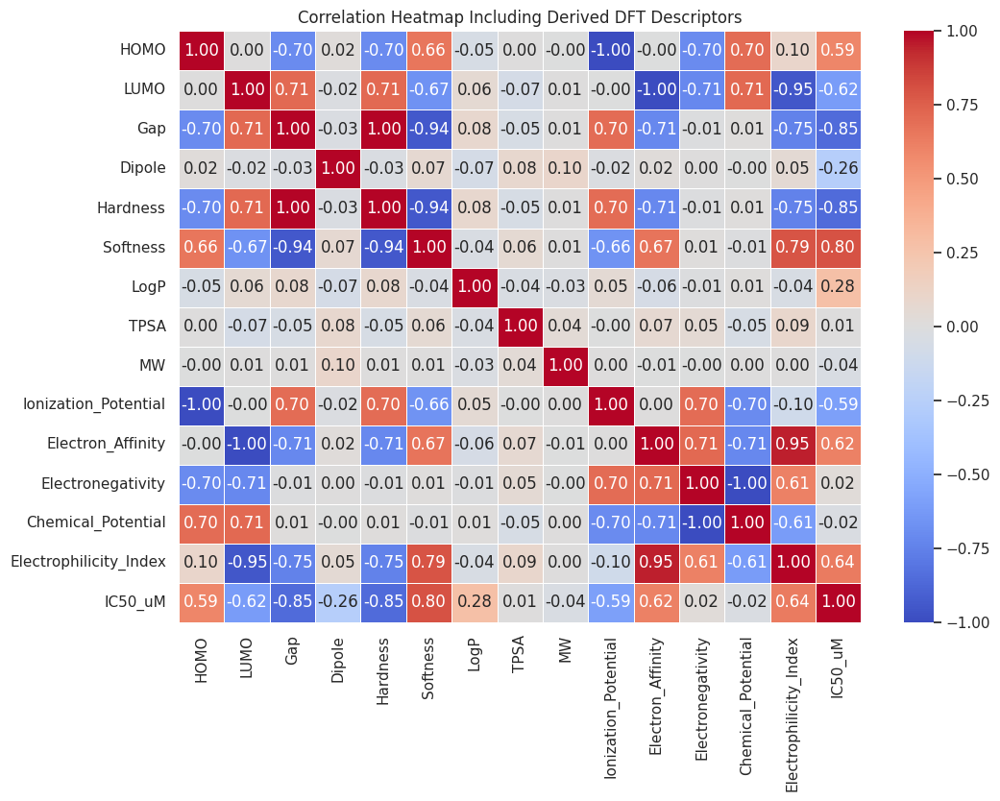

In [ ]:
all_numeric_cols = descriptor_cols + derived_cols + ["IC50_uM"]

new_corr = df[all_numeric_cols].corr()

plt.figure(figsize=(11, 8.5))
sns.heatmap(
    new_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap Including Derived DFT Descriptors")
plt.tight_layout()
plt.show()

In [ ]:
output_path = "/content/drive/MyDrive/Colab Notebooks/Dr. Khan/Anticancer/Azo_Schiff_Updated_DFT_Descriptors.csv"



df.to_csv(output_path, index=False)

print("Updated dataset saved at:", output_path)

Updated dataset saved at: /content/drive/MyDrive/Colab Notebooks/Dr. Khan/Anticancer/Azo_Schiff_Updated_DFT_Descriptors.csv


In [ ]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.manifold import TSNE
import umap.umap_ as umap

In [ ]:
data = df.copy()

print("Original dataset shape:", data.shape)
data.head()

Original dataset shape: (350, 20)


,Compound ID,Ligand,Metal,Cell line,IC50_uM,DOI,HOMO,LUMO,Gap,Dipole,Hardness,Softness,LogP,TPSA,MW,Ionization_Potential,Electron_Affinity,Electronegativity,Chemical_Potential,Electrophilicity_Index
0,ASB-001,Acetylacetone,Ni,MCF-7,77.28,10.1000/synth.001,-6.742,-2.540,4.202,3.05,2.101,0.476,4.32,104.44,672.56,6.742,2.540,4.6410,-4.6410,5.125864
1,ASB-002,Acetylacetone,Cu,HepG2,78.38,10.1000/synth.002,-6.585,-2.642,3.943,6.20,1.972,0.507,3.34,108.76,588.58,6.585,2.642,4.6135,-4.6135,5.396649
2,ASB-003,Naphthaldehyde,Pd,MCF-7,128.23,10.1000/synth.003,-4.938,-3.184,1.754,7.89,0.877,1.140,4.11,67.43,348.41,4.938,3.184,4.0610,-4.0610,9.402349
3,ASB-004,Acetylacetone,Ni,MCF-7,76.53,10.1000/synth.004,-5.926,-2.338,3.588,4.05,1.794,0.557,1.68,34.78,482.15,5.926,2.338,4.1320,-4.1320,4.758479
4,ASB-005,Naphthaldehyde,Pd,MCF-7,84.41,10.1000/synth.005,-4.892,-1.716,3.176,8.35,1.588,0.630,3.43,107.50,300.16,4.892,1.716,3.3040,-3.3040,3.437159


In [ ]:
drop_cols = ["Compound ID", "DOI"]

data_model = data.drop(columns=drop_cols, errors="ignore")

print("Dataset after removing non-predictive columns:", data_model.shape)
data_model.head()

Dataset after removing non-predictive columns: (350, 18)


,Ligand,Metal,Cell line,IC50_uM,HOMO,LUMO,Gap,Dipole,Hardness,Softness,LogP,TPSA,MW,Ionization_Potential,Electron_Affinity,Electronegativity,Chemical_Potential,Electrophilicity_Index
0,Acetylacetone,Ni,MCF-7,77.28,-6.742,-2.540,4.202,3.05,2.101,0.476,4.32,104.44,672.56,6.742,2.540,4.6410,-4.6410,5.125864
1,Acetylacetone,Cu,HepG2,78.38,-6.585,-2.642,3.943,6.20,1.972,0.507,3.34,108.76,588.58,6.585,2.642,4.6135,-4.6135,5.396649
2,Naphthaldehyde,Pd,MCF-7,128.23,-4.938,-3.184,1.754,7.89,0.877,1.140,4.11,67.43,348.41,4.938,3.184,4.0610,-4.0610,9.402349
3,Acetylacetone,Ni,MCF-7,76.53,-5.926,-2.338,3.588,4.05,1.794,0.557,1.68,34.78,482.15,5.926,2.338,4.1320,-4.1320,4.758479
4,Naphthaldehyde,Pd,MCF-7,84.41,-4.892,-1.716,3.176,8.35,1.588,0.630,3.43,107.50,300.16,4.892,1.716,3.3040,-3.3040,3.437159


In [ ]:
target_col = "IC50_uM"

print("Target column:", target_col)
print(data_model[target_col].describe())

Target column: IC50_uM
count    350.000000
mean      86.616229
std       19.380916
min       39.060000
25%       74.557500
50%       86.900000
75%       99.730000
max      135.800000
Name: IC50_uM, dtype: float64


In [ ]:
X = data_model.drop(columns=[target_col])
y = data_model[target_col]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (350, 17)
Target shape: (350,)


In [ ]:
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numeric_cols)

Categorical Columns: ['Ligand', 'Metal', 'Cell line']
Numerical Columns: ['HOMO', 'LUMO', 'Gap', 'Dipole', 'Hardness', 'Softness', 'LogP', 'TPSA', 'MW', 'Ionization_Potential', 'Electron_Affinity', 'Electronegativity', 'Chemical_Potential', 'Electrophilicity_Index']


In [ ]:
X_encoded = X.copy()

label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col].astype(str))
    label_encoders[col] = le

X_encoded.head()

,Ligand,Metal,Cell line,HOMO,LUMO,Gap,Dipole,Hardness,Softness,LogP,TPSA,MW,Ionization_Potential,Electron_Affinity,Electronegativity,Chemical_Potential,Electrophilicity_Index
0,1,3,4,-6.742,-2.540,4.202,3.05,2.101,0.476,4.32,104.44,672.56,6.742,2.540,4.6410,-4.6410,5.125864
1,1,1,3,-6.585,-2.642,3.943,6.20,1.972,0.507,3.34,108.76,588.58,6.585,2.642,4.6135,-4.6135,5.396649
2,3,4,4,-4.938,-3.184,1.754,7.89,0.877,1.140,4.11,67.43,348.41,4.938,3.184,4.0610,-4.0610,9.402349
3,1,3,4,-5.926,-2.338,3.588,4.05,1.794,0.557,1.68,34.78,482.15,5.926,2.338,4.1320,-4.1320,4.758479
4,3,4,4,-4.892,-1.716,3.176,8.35,1.588,0.630,3.43,107.50,300.16,4.892,1.716,3.3040,-3.3040,3.437159


In [ ]:
for col, le in label_encoders.items():
    print(f"\nEncoding for {col}:")
    for original, encoded in zip(le.classes_, le.transform(le.classes_)):
        print(original, "->", encoded)


Encoding for Ligand:
2-Hydroxybenzaldehyde -> 0
Acetylacetone -> 1
Anisaldehyde -> 2
Naphthaldehyde -> 3
Salicylaldehyde -> 4
Vanillin -> 5

Encoding for Metal:
Co -> 0
Cu -> 1
Fe -> 2
Ni -> 3
Pd -> 4
Pt -> 5
Ru -> 6
Zn -> 7

Encoding for Cell line:
A549 -> 0
HCT116 -> 1
HeLa -> 2
HepG2 -> 3
MCF-7 -> 4
MDA-MB-231 -> 5
PC-3 -> 6


In [ ]:
imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X_encoded),
    columns=X_encoded.columns
)

print("Missing values after imputation:")
print(X_imputed.isnull().sum().sum())

X_imputed.head()

Missing values after imputation:
0


,Ligand,Metal,Cell line,HOMO,LUMO,Gap,Dipole,Hardness,Softness,LogP,TPSA,MW,Ionization_Potential,Electron_Affinity,Electronegativity,Chemical_Potential,Electrophilicity_Index
0,1.0,3.0,4.0,-6.742,-2.540,4.202,3.05,2.101,0.476,4.32,104.44,672.56,6.742,2.540,4.6410,-4.6410,5.125864
1,1.0,1.0,3.0,-6.585,-2.642,3.943,6.20,1.972,0.507,3.34,108.76,588.58,6.585,2.642,4.6135,-4.6135,5.396649
2,3.0,4.0,4.0,-4.938,-3.184,1.754,7.89,0.877,1.140,4.11,67.43,348.41,4.938,3.184,4.0610,-4.0610,9.402349
3,1.0,3.0,4.0,-5.926,-2.338,3.588,4.05,1.794,0.557,1.68,34.78,482.15,5.926,2.338,4.1320,-4.1320,4.758479
4,3.0,4.0,4.0,-4.892,-1.716,3.176,8.35,1.588,0.630,3.43,107.50,300.16,4.892,1.716,3.3040,-3.3040,3.437159


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

X_scaled_df = pd.DataFrame(X_scaled, columns=X_imputed.columns)

X_scaled_df.head()

,Ligand,Metal,Cell line,HOMO,LUMO,Gap,Dipole,Hardness,Softness,LogP,TPSA,MW,Ionization_Potential,Electron_Affinity,Electronegativity,Chemical_Potential,Electrophilicity_Index
0,-0.873709,-0.236401,0.487380,-1.740987,-0.789027,0.661577,-1.028238,0.661613,-0.692426,0.847278,0.709500,1.306380,1.740987,0.789027,1.784416,-1.784416,0.401790
1,-0.873709,-1.098279,-0.005634,-1.503131,-0.941565,0.385899,0.349101,0.386985,-0.524983,0.246098,0.849780,0.645812,1.503131,0.941565,1.725885,-1.725885,0.559512
2,0.286815,0.194538,0.487380,0.992081,-1.752110,-1.944066,1.088054,-1.944158,2.894089,0.718454,-0.492295,-1.243313,-0.992081,1.752110,0.549949,-0.549949,2.892690
3,-0.873709,-0.236401,0.487380,-0.504743,-0.486942,0.008038,-0.590988,0.008041,-0.254914,-0.772227,-1.552510,-0.191343,0.504743,0.486942,0.701065,-0.701065,0.187802
4,0.286815,0.194538,0.487380,1.061771,0.443240,-0.430494,1.289190,-0.430512,0.139386,0.301309,0.808865,-1.622837,-1.061771,-0.443240,-1.061243,1.061243,-0.581820


In [ ]:
scaling_comparison = pd.DataFrame({
    "Before Scaling Mean": X_imputed.mean(),
    "Before Scaling Std": X_imputed.std(),
    "After Scaling Mean": X_scaled_df.mean(),
    "After Scaling Std": X_scaled_df.std()
})

scaling_comparison

,Before Scaling Mean,Before Scaling Std,After Scaling Mean,After Scaling Std
Ligand,2.505714,1.725827,-2.030122e-17,1.001432
Metal,3.548571,2.323836,3.806479e-17,1.001432
Cell line,3.011429,2.031242,-1.002373e-16,1.001432
HOMO,-5.592837,0.661009,-7.270375e-16,1.001432
LUMO,-2.012389,0.669643,3.121313e-16,1.001432
Gap,3.580449,0.940844,2.287059e-16,1.001432
Dipole,5.401600,2.290292,-7.612958e-17,1.001432
Hardness,1.790223,0.470399,6.280690e-17,1.001432
Softness,0.604194,0.185403,-4.390139e-16,1.001432
LogP,2.938829,1.632462,1.700227e-16,1.001432


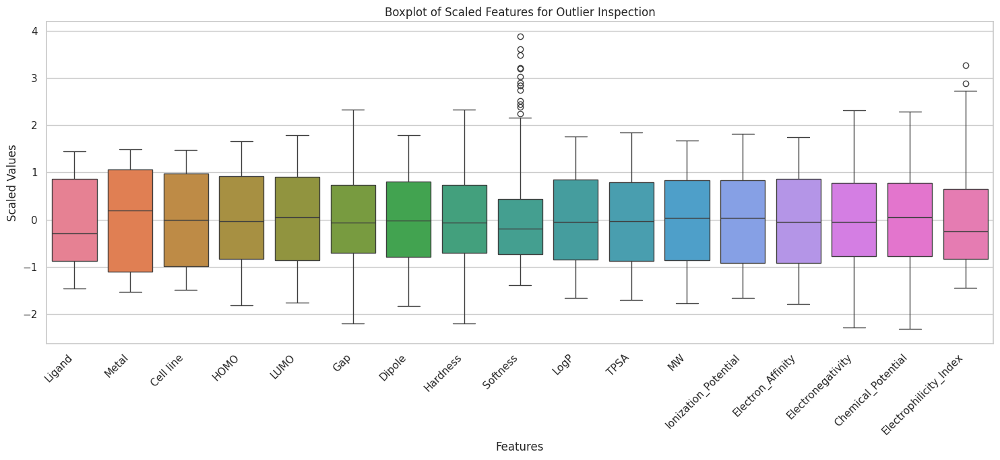

In [ ]:
plt.figure(figsize=(15, 7))
sns.boxplot(data=X_scaled_df)
plt.xticks(rotation=45, ha="right")
plt.title("Boxplot of Scaled Features for Outlier Inspection")
plt.xlabel("Features")
plt.ylabel("Scaled Values")
plt.tight_layout()
plt.show()

In [ ]:
def activity_class(ic50):
    if ic50 < 50:
        return "High Activity"
    elif ic50 <= 100:
        return "Moderate Activity"
    else:
        return "Low Activity"

activity_labels = y.apply(activity_class)

activity_labels.value_counts()

,count
IC50_uM,
Moderate Activity,250
Low Activity,87
High Activity,13


/tmp/ipykernel_709/1686543909.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=activity_labels, palette="viridis")


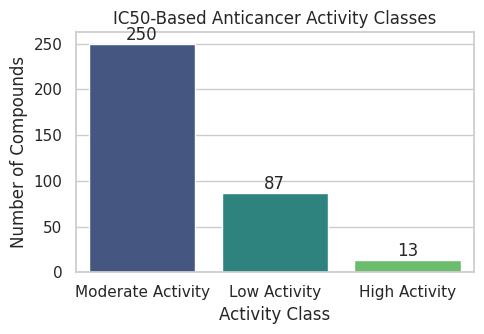

In [ ]:
plt.figure(figsize=(5, 3.5))
ax = sns.countplot(x=activity_labels, palette="viridis")

plt.title("IC50-Based Anticancer Activity Classes")
plt.xlabel("Activity Class")
plt.ylabel("Number of Compounds")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [ ]:
# t-SNE dimensionality reduction
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

# UMAP dimensionality reduction
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42
)

X_umap = umap_model.fit_transform(X_scaled)

# Create dataframe for plotting
embedding_df = pd.DataFrame({
    "tSNE_1": X_tsne[:, 0],
    "tSNE_2": X_tsne[:, 1],
    "UMAP_1": X_umap[:, 0],
    "UMAP_2": X_umap[:, 1],
    "Activity_Class": activity_labels.values,
    "Metal": data["Metal"].values,
    "IC50_uM": y.values
})

embedding_df.head()

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,tSNE_1,tSNE_2,UMAP_1,UMAP_2,Activity_Class,Metal,IC50_uM
0,-4.467000,12.198830,1.418129,1.722690,Moderate Activity,Ni,77.28
1,-5.629731,12.761613,1.146762,1.615377,Moderate Activity,Cu,78.38
2,-17.616461,-7.266953,5.348385,2.693250,Low Activity,Pd,128.23
3,-1.880352,5.874159,1.583747,2.870970,Moderate Activity,Ni,76.53
4,-4.093767,-12.223809,3.822079,4.759230,Moderate Activity,Pd,84.41


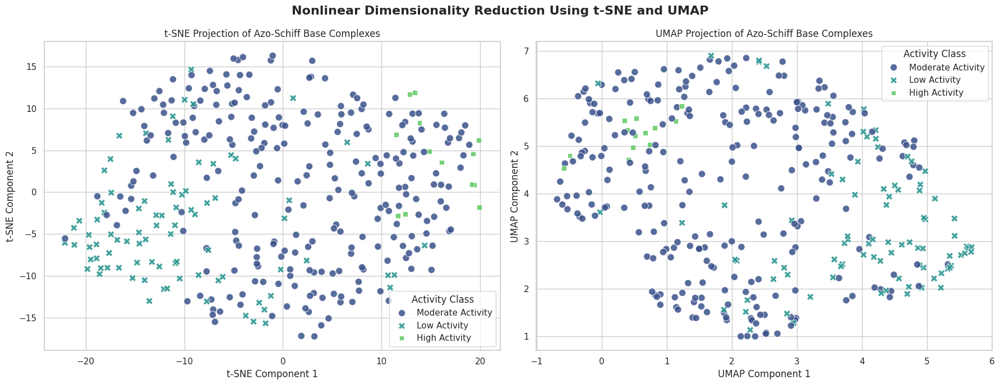

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.scatterplot(
    data=embedding_df,
    x="tSNE_1",
    y="tSNE_2",
    hue="Activity_Class",
    style="Activity_Class",
    s=80,
    alpha=0.85,
    ax=axes[0],
    palette="viridis"
)

axes[0].set_title("t-SNE Projection of Azo-Schiff Base Complexes")
axes[0].set_xlabel("t-SNE Component 1")
axes[0].set_ylabel("t-SNE Component 2")
axes[0].legend(title="Activity Class")

sns.scatterplot(
    data=embedding_df,
    x="UMAP_1",
    y="UMAP_2",
    hue="Activity_Class",
    style="Activity_Class",
    s=80,
    alpha=0.85,
    ax=axes[1],
    palette="viridis"
)

axes[1].set_title("UMAP Projection of Azo-Schiff Base Complexes")
axes[1].set_xlabel("UMAP Component 1")
axes[1].set_ylabel("UMAP Component 2")
axes[1].legend(title="Activity Class")

plt.suptitle("Nonlinear Dimensionality Reduction Using t-SNE and UMAP", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

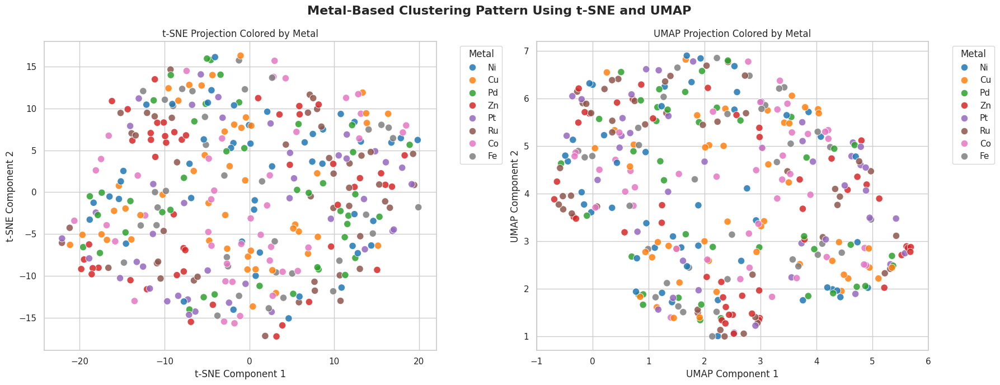

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.scatterplot(
    data=embedding_df,
    x="tSNE_1",
    y="tSNE_2",
    hue="Metal",
    s=80,
    alpha=0.85,
    ax=axes[0],
    palette="tab10"
)

axes[0].set_title("t-SNE Projection Colored by Metal")
axes[0].set_xlabel("t-SNE Component 1")
axes[0].set_ylabel("t-SNE Component 2")
axes[0].legend(title="Metal", bbox_to_anchor=(1.05, 1), loc="upper left")

sns.scatterplot(
    data=embedding_df,
    x="UMAP_1",
    y="UMAP_2",
    hue="Metal",
    s=80,
    alpha=0.85,
    ax=axes[1],
    palette="tab10"
)

axes[1].set_title("UMAP Projection Colored by Metal")
axes[1].set_xlabel("UMAP Component 1")
axes[1].set_ylabel("UMAP Component 2")
axes[1].legend(title="Metal", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.suptitle("Metal-Based Clustering Pattern Using t-SNE and UMAP", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

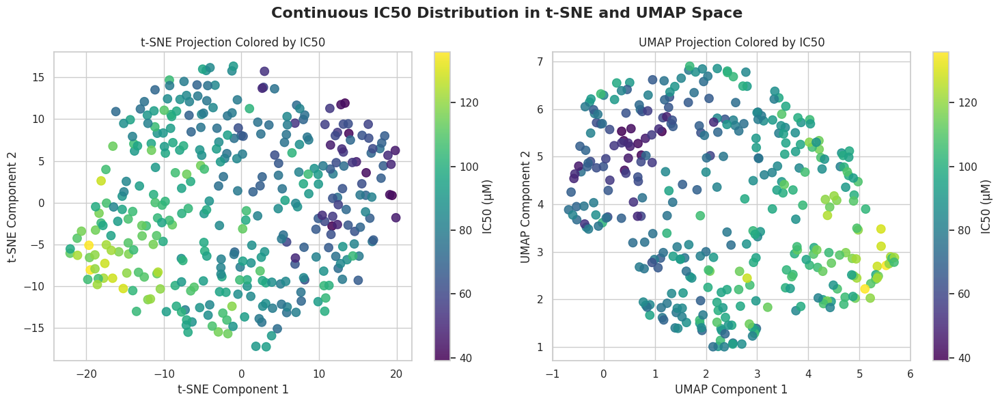

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

scatter1 = axes[0].scatter(
    embedding_df["tSNE_1"],
    embedding_df["tSNE_2"],
    c=embedding_df["IC50_uM"],
    cmap="viridis",
    s=80,
    alpha=0.85
)

axes[0].set_title("t-SNE Projection Colored by IC50")
axes[0].set_xlabel("t-SNE Component 1")
axes[0].set_ylabel("t-SNE Component 2")
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label("IC50 (µM)")

scatter2 = axes[1].scatter(
    embedding_df["UMAP_1"],
    embedding_df["UMAP_2"],
    c=embedding_df["IC50_uM"],
    cmap="viridis",
    s=80,
    alpha=0.85
)

axes[1].set_title("UMAP Projection Colored by IC50")
axes[1].set_xlabel("UMAP Component 1")
axes[1].set_ylabel("UMAP Component 2")
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label("IC50 (µM)")

plt.suptitle("Continuous IC50 Distribution in t-SNE and UMAP Space", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 1. Train-Test Split 70:30
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed,
    y,
    test_size=0.30,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (245, 17)
Testing feature shape: (105, 17)
Training target shape: (245,)
Testing target shape: (105,)


Training Random Forest...
Training XGBoost...
Training CatBoost...
Training LightGBM...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000136 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1162
[LightGBM] [Info] Number of data points in the train set: 245, number of used features: 17
[LightGBM] [Info] Start training from score 87.114653
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Training SVR...

All models trained successfully.

Train and Test Performance Results:


,Model,Train R2,Train MAE,Train MSE,Train RMSE,Train MAPE (%),Test R2,Test MAE,Test MSE,Test RMSE,Test MAPE (%)
2,CatBoost,0.9857,1.8558,5.1857,2.2772,2.2316,0.8933,5.3840,42.9651,6.5548,7.0627
1,XGBoost,0.9988,0.4913,0.4251,0.6520,0.5885,0.8790,5.5816,48.7258,6.9804,7.2722
3,LightGBM,0.9938,1.1981,2.2438,1.4979,1.4481,0.8752,5.7457,50.2629,7.0896,7.3758
0,Random Forest,0.9819,2.0853,6.5526,2.5598,2.5237,0.8676,6.1273,53.3169,7.3018,8.1509
4,SVR,0.9313,3.5101,24.8487,4.9848,4.3551,0.8667,5.9126,53.6807,7.3267,7.9138



Results saved at:
/content/drive/MyDrive/Azo_Schiff_5ML_70_30_Results.csv


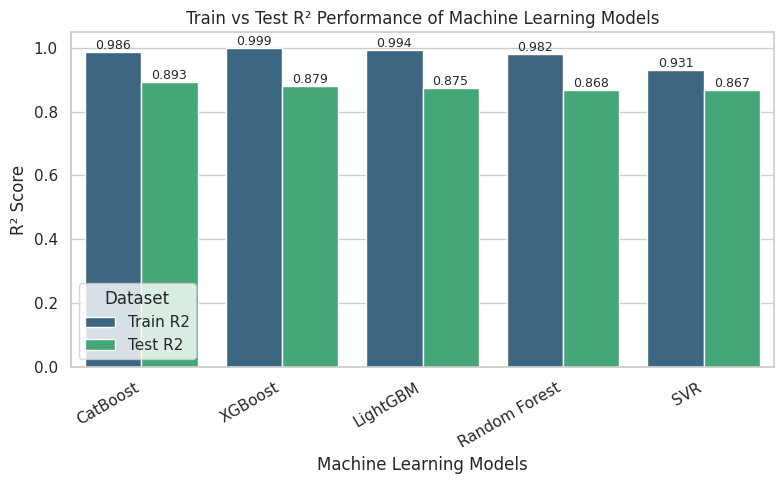

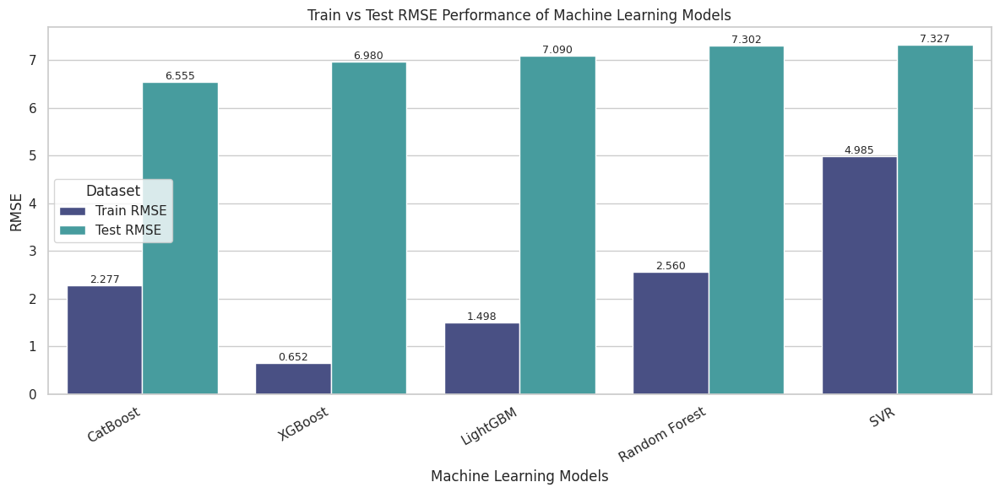

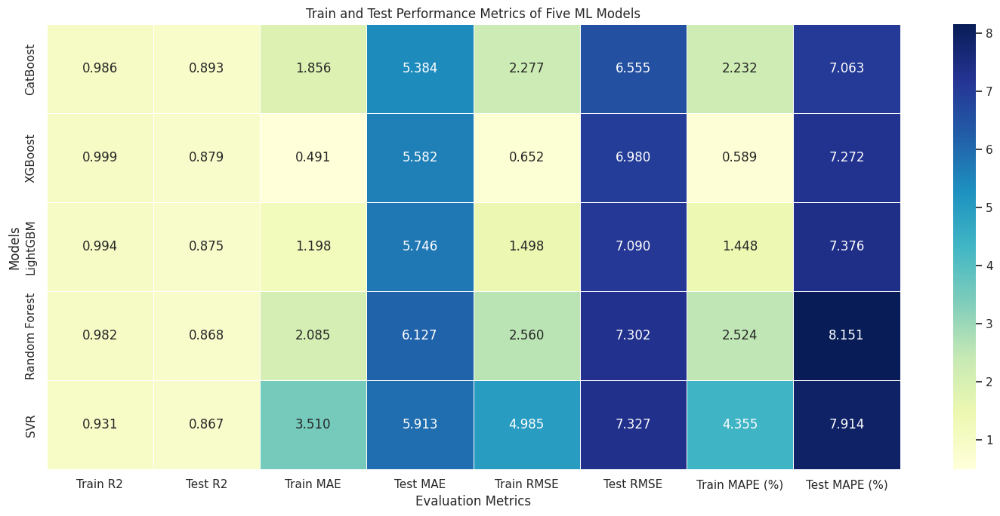


Best Model Based on Test R²:
CatBoost


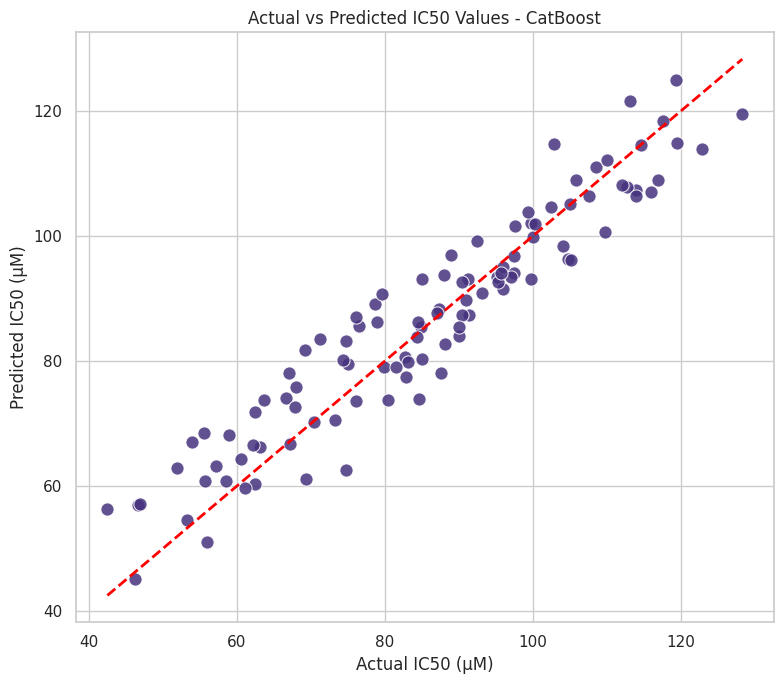

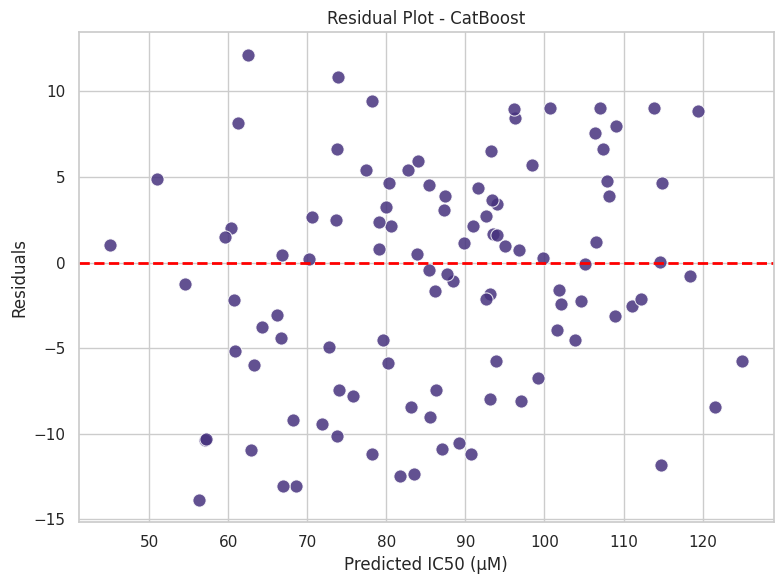

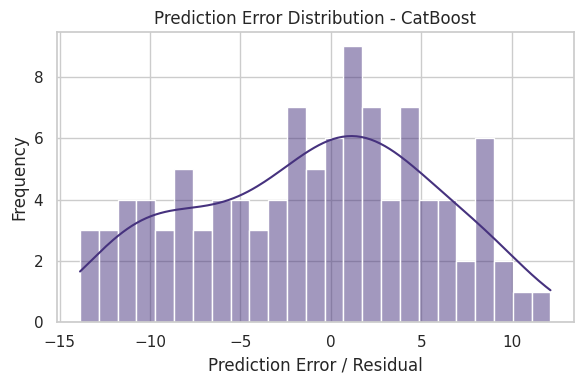


Best Model Prediction Table:


,Actual_IC50,Predicted_IC50,Error,Absolute_Error
0,42.47,56.342024,-13.872024,13.872024
1,57.19,63.200545,-6.010545,6.010545
2,55.91,51.033961,4.876039,4.876039
3,87.58,78.134078,9.445922,9.445922
4,105.03,105.097392,-0.067392,0.067392
5,89.98,84.038453,5.941547,5.941547
6,109.73,100.722896,9.007104,9.007104
7,95.92,91.589698,4.330302,4.330302
8,55.49,68.551849,-13.061849,13.061849
9,84.94,85.404778,-0.464778,0.464778



Best model prediction table saved at:
/content/drive/MyDrive/Azo_Schiff_Best_Model_70_30_Predictions.csv


In [ ]:
# ============================================================
# APPLY 5 MACHINE LEARNING MODELS AFTER 70:30 SPLIT
# Models: Random Forest, XGBoost, CatBoost, LightGBM, SVR
# Target: IC50_uM
# Required variables before running:
# X_train_scaled, X_test_scaled, y_train, y_test
# ============================================================

# Install required libraries
!pip install xgboost lightgbm catboost -q

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Plot settings
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

# ============================================================
# Define Evaluation Function
# ============================================================

def evaluate_regression(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100

    return r2, mae, mse, rmse, mape


# ============================================================
# Define 5 Machine Learning Models
# ============================================================

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=42
    ),

    "CatBoost": CatBoostRegressor(
        iterations=300,
        learning_rate=0.05,
        depth=5,
        loss_function="RMSE",
        verbose=0,
        random_state=42
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        random_state=42
    ),

    "SVR": SVR(
        kernel="rbf",
        C=10,
        gamma="scale",
        epsilon=0.1
    )
}

# ============================================================
# Scale the data after train-test split
# ============================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create DataFrames for scaled data to retain column names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_imputed.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_imputed.columns)


# ============================================================
# Train and Evaluate Models
# ============================================================

results = []
predictions = {}
trained_models = {}

for model_name, model in models.items():

    print(f"Training {model_name}...")

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)

    # Train metrics
    train_r2, train_mae, train_mse, train_rmse, train_mape = evaluate_regression(y_train, y_train_pred)

    # Test metrics
    test_r2, test_mae, test_mse, test_rmse, test_mape = evaluate_regression(y_test, y_test_pred)

    # Store results
    results.append({
        "Model": model_name,
        "Train R2": train_r2,
        "Train MAE": train_mae,
        "Train MSE": train_mse,
        "Train RMSE": train_rmse,
        "Train MAPE (%)": train_mape,
        "Test R2": test_r2,
        "Test MAE": test_mae,
        "Test MSE": test_mse,
        "Test RMSE": test_rmse,
        "Test MAPE (%)": test_mape
    })

    # Store predictions
    predictions[model_name] = {
        "Train Actual": np.array(y_train),
        "Train Predicted": y_train_pred,
        "Test Actual": np.array(y_test),
        "Test Predicted": y_test_pred
    }

    trained_models[model_name] = model

print("\nAll models trained successfully.")


# ============================================================
# Results Table
# ============================================================

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="Test R2", ascending=False)

paper_results_df = results_df.copy()
numeric_cols = paper_results_df.select_dtypes(include=["float64", "float32"]).columns
paper_results_df[numeric_cols] = paper_results_df[numeric_cols].round(4)

print("\nTrain and Test Performance Results:")
display(paper_results_df)


# ============================================================
# Save Results
# ============================================================

results_path = "/content/drive/MyDrive/Azo_Schiff_5ML_70_30_Results.csv"
paper_results_df.to_csv(results_path, index=False)

print("\nResults saved at:")
print(results_path)


# ============================================================
# Plot 1: Train vs Test R2
# ============================================================

r2_plot_df = paper_results_df[["Model", "Train R2", "Test R2"]].melt(
    id_vars="Model",
    var_name="Dataset",
    value_name="R2 Score"
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=r2_plot_df,
    x="Model",
    y="R2 Score",
    hue="Dataset",
    palette="viridis"
)

plt.title("Train vs Test R² Performance of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R² Score")
plt.xticks(rotation=30, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=9)

plt.tight_layout()
plt.show()


# ============================================================
# Plot 2: Train vs Test RMSE
# ============================================================

rmse_plot_df = paper_results_df[["Model", "Train RMSE", "Test RMSE"]].melt(
    id_vars="Model",
    var_name="Dataset",
    value_name="RMSE"
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=rmse_plot_df,
    x="Model",
    y="RMSE",
    hue="Dataset",
    palette="mako"
)

plt.title("Train vs Test RMSE Performance of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")
plt.xticks(rotation=30, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=9)

plt.tight_layout()
plt.show()


# ============================================================
# Plot 3: Performance Heatmap
# ============================================================

heatmap_data = paper_results_df.set_index("Model")[
    [
        "Train R2", "Test R2",
        "Train MAE", "Test MAE",
        "Train RMSE", "Test RMSE",
        "Train MAPE (%)", "Test MAPE (%)"
    ]
]

plt.figure(figsize=(15, 7))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Train and Test Performance Metrics of Five ML Models")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Models")
plt.tight_layout()
plt.show()


# ============================================================
# Best Model Selection
# ============================================================

best_model_name = paper_results_df.iloc[0]["Model"]

print("\nBest Model Based on Test R²:")
print(best_model_name)

best_y_actual = predictions[best_model_name]["Test Actual"]
best_y_pred = predictions[best_model_name]["Test Predicted"]


# ============================================================
# Plot 4: Actual vs Predicted for Best Model
# ============================================================

plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=best_y_actual,
    y=best_y_pred,
    s=90,
    alpha=0.85
)

min_val = min(best_y_actual.min(), best_y_pred.min())
max_val = max(best_y_actual.max(), best_y_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2)

plt.title(f"Actual vs Predicted IC50 Values - {best_model_name}")
plt.xlabel("Actual IC50 (µM)")
plt.ylabel("Predicted IC50 (µM)")
plt.tight_layout()
plt.show()


# ============================================================
# Plot 5: Residual Plot for Best Model
# ============================================================

residuals = best_y_actual - best_y_pred

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=best_y_pred,
    y=residuals,
    s=90,
    alpha=0.85
)

plt.axhline(0, color="red", linestyle="--", linewidth=2)

plt.title(f"Residual Plot - {best_model_name}")
plt.xlabel("Predicted IC50 (µM)")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()


# ============================================================
# Plot 6: Error Distribution for Best Model
# ============================================================

plt.figure(figsize=(6, 4))

sns.histplot(residuals, kde=True, bins=25)

plt.title(f"Prediction Error Distribution - {best_model_name}")
plt.xlabel("Prediction Error / Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ============================================================
# Best Model Prediction Table
# ============================================================

best_prediction_table = pd.DataFrame({
    "Actual_IC50": best_y_actual,
    "Predicted_IC50": best_y_pred
})

best_prediction_table["Error"] = best_prediction_table["Actual_IC50"] - best_prediction_table["Predicted_IC50"]
best_prediction_table["Absolute_Error"] = abs(best_prediction_table["Error"])

print("\nBest Model Prediction Table:")
display(best_prediction_table.head(20))


# ============================================================
# Save Best Model Predictions
# ============================================================

prediction_path = "/content/drive/MyDrive/Azo_Schiff_Best_Model_70_30_Predictions.csv"
best_prediction_table.to_csv(prediction_path, index=False)

print("\nBest model prediction table saved at:")
print(prediction_path)

SHAP values generated successfully.


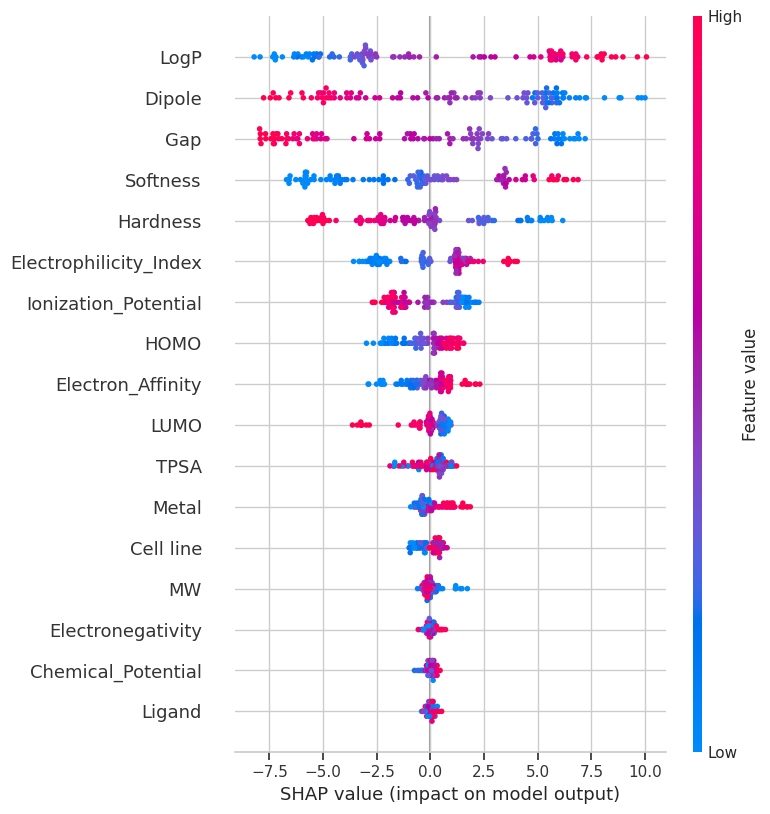

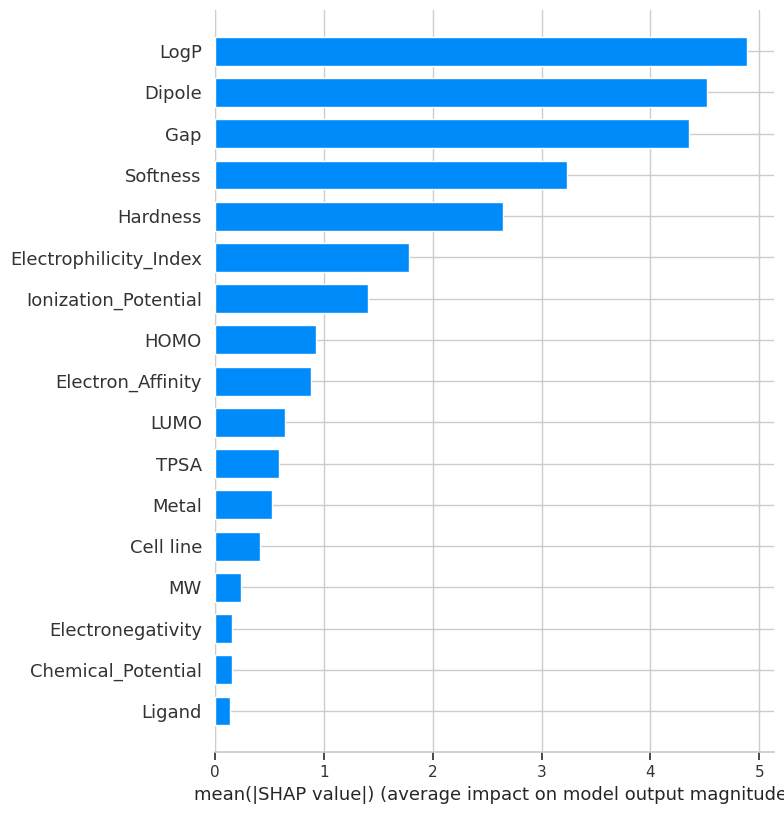

,Feature,Mean_ABS_SHAP
9,LogP,4.891449
6,Dipole,4.521787
5,Gap,4.354119
8,Softness,3.237117
7,Hardness,2.647447
16,Electrophilicity_Index,1.777804
12,Ionization_Potential,1.406862
3,HOMO,0.929839
13,Electron_Affinity,0.878183
4,LUMO,0.644875


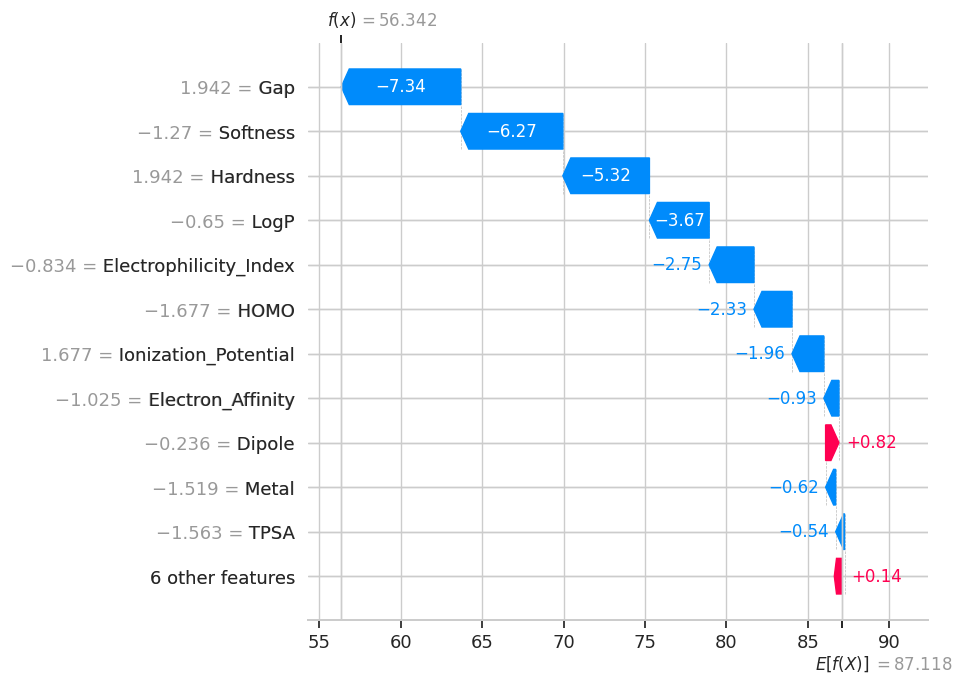

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# SHAP explainer
shap_explainer = shap.TreeExplainer(trained_models["CatBoost"])

# SHAP values
shap_values = shap_explainer.shap_values(X_test_scaled)

print("SHAP values generated successfully.")

# SHAP summary plot
shap.summary_plot(
    shap_values,
    X_test_scaled_df,
    feature_names=X_test_scaled_df.columns
)

# SHAP bar plot
shap.summary_plot(
    shap_values,
    X_test_scaled_df,
    feature_names=X_test_scaled_df.columns,
    plot_type="bar"
)

# SHAP feature importance table
shap_importance = pd.DataFrame({
    "Feature": X_test_scaled_df.columns,
    "Mean_ABS_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values(by="Mean_ABS_SHAP", ascending=False)

display(shap_importance)

# SHAP waterfall plot for one sample
sample_index = 0

shap_exp = shap.Explanation(
    values=shap_values[sample_index],
    base_values=shap_explainer.expected_value,
    data=X_test_scaled_df.iloc[sample_index],
    feature_names=X_test_scaled_df.columns
)

shap.plots.waterfall(shap_exp, max_display=12)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Actual IC50: 42.47
Predicted IC50: 56.34202379614143


,Feature Condition,Contribution
0,Gap > 0.72,-9.351448
1,Softness <= -0.73,-6.570815
2,Hardness > 0.72,-4.399901
3,-0.84 < LogP <= -0.01,-3.697404
4,-0.77 < Dipole <= 0.05,3.004773
5,Electrophilicity_Index <= -0.79,-2.473098
6,HOMO <= -0.85,-1.519740
7,Ionization_Potential > 0.85,-1.428131
8,Electron_Affinity <= -0.74,-1.346321
9,LUMO > 0.74,-1.154154


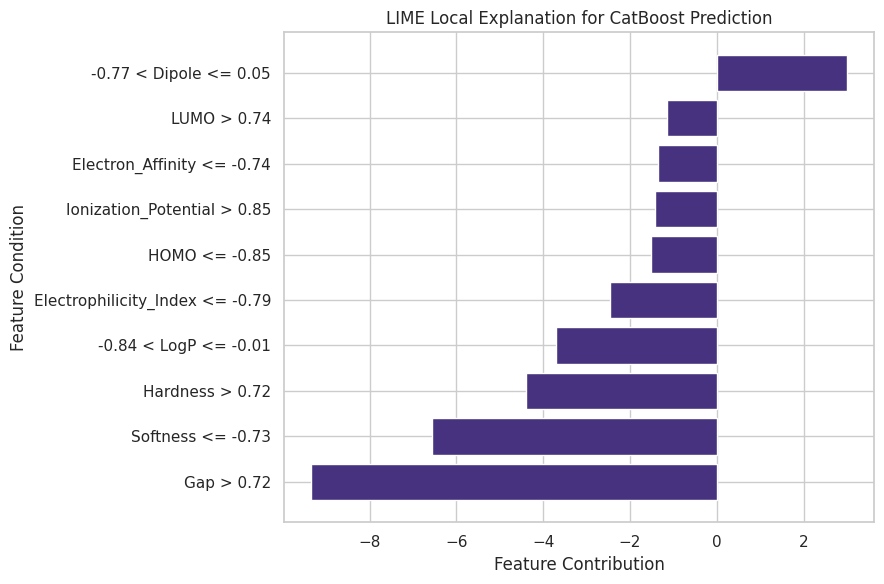

In [ ]:
# ============================
# LIME Code for CatBoost
# Required: trained_models["CatBoost"], X_train_scaled_df, X_test_scaled_df, y_test
# ============================

!pip install lime -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer

# LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=np.array(X_train_scaled_df),
    feature_names=X_train_scaled_df.columns.tolist(),
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

# Explain one test sample
sample_index = 0

lime_exp = lime_explainer.explain_instance(
    data_row=X_test_scaled_df.iloc[sample_index].values,
    predict_fn=trained_models["CatBoost"].predict,
    num_features=10
)

actual_value = y_test.iloc[sample_index] if hasattr(y_test, "iloc") else y_test.values[sample_index]
predicted_value = trained_models["CatBoost"].predict(X_test_scaled_df.iloc[[sample_index]])[0]

print("Actual IC50:", actual_value)
print("Predicted IC50:", predicted_value)

# Show LIME explanation
lime_exp.show_in_notebook(show_table=True)

# LIME table
lime_df = pd.DataFrame(
    lime_exp.as_list(),
    columns=["Feature Condition", "Contribution"]
)

display(lime_df)

# LIME bar plot
lime_df_sorted = lime_df.sort_values(by="Contribution", ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(
    lime_df_sorted["Feature Condition"],
    lime_df_sorted["Contribution"]
)

plt.title("LIME Local Explanation for CatBoost Prediction")
plt.xlabel("Feature Contribution")
plt.ylabel("Feature Condition")
plt.tight_layout()
plt.show()

Random selected sample indices: [30 65 64]

LIME Explanation for Test Sample Index: 30
Actual IC50: 87.31
Predicted IC50: 88.3800053189117


,Feature Condition,Contribution,Sample_Index,Actual_IC50,Predicted_IC50
0,Gap > 0.72,-9.126299,30,87.31,88.380005
1,LogP > 0.83,8.213484,30,87.31,88.380005
2,Dipole <= -0.77,7.371894,30,87.31,88.380005
3,Softness <= -0.73,-6.519187,30,87.31,88.380005
4,Hardness > 0.72,-4.666209,30,87.31,88.380005
5,Ionization_Potential > 0.85,-1.631536,30,87.31,88.380005
6,HOMO <= -0.85,-1.596840,30,87.31,88.380005
7,-0.79 < Electrophilicity_Index <= -0.25,-0.898075,30,87.31,88.380005
8,-0.88 < TPSA <= 0.00,0.822772,30,87.31,88.380005
9,-0.83 < LUMO <= 0.07,0.737130,30,87.31,88.380005


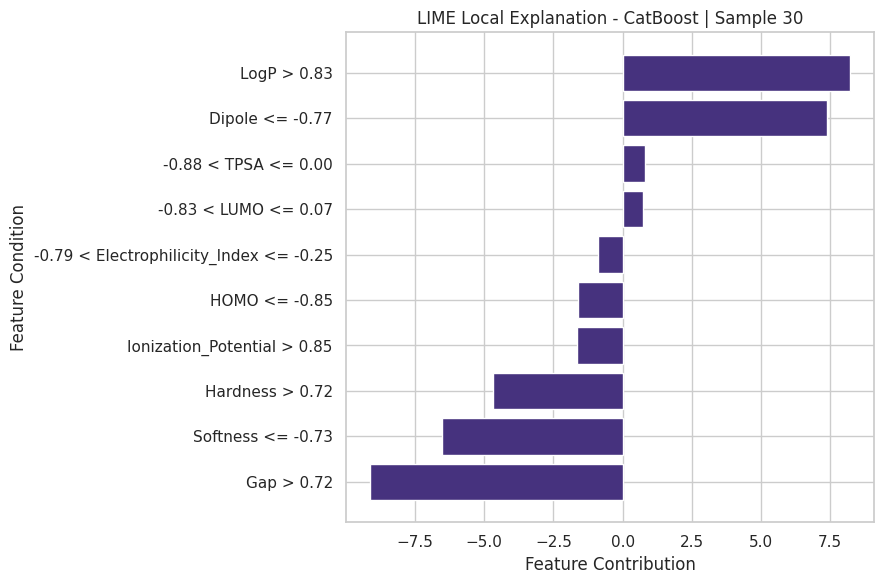


LIME Explanation for Test Sample Index: 65
Actual IC50: 91.23
Predicted IC50: 93.04942594924944


,Feature Condition,Contribution,Sample_Index,Actual_IC50,Predicted_IC50
0,LogP <= -0.84,-7.836473,65,91.23,93.049426
1,Dipole <= -0.77,7.570126,65,91.23,93.049426
2,-0.69 < Gap <= -0.05,3.044883,65,91.23,93.049426
3,Electrophilicity_Index > 0.59,2.257692,65,91.23,93.049426
4,-0.21 < Softness <= 0.42,2.098565,65,91.23,93.049426
5,Electron_Affinity > 0.83,1.304317,65,91.23,93.049426
6,-0.04 < Ionization_Potential <= 0.85,-1.132524,65,91.23,93.049426
7,-0.69 < Hardness <= -0.05,0.903142,65,91.23,93.049426
8,TPSA > 0.77,-0.777543,65,91.23,93.049426
9,Metal > 0.65,0.770549,65,91.23,93.049426


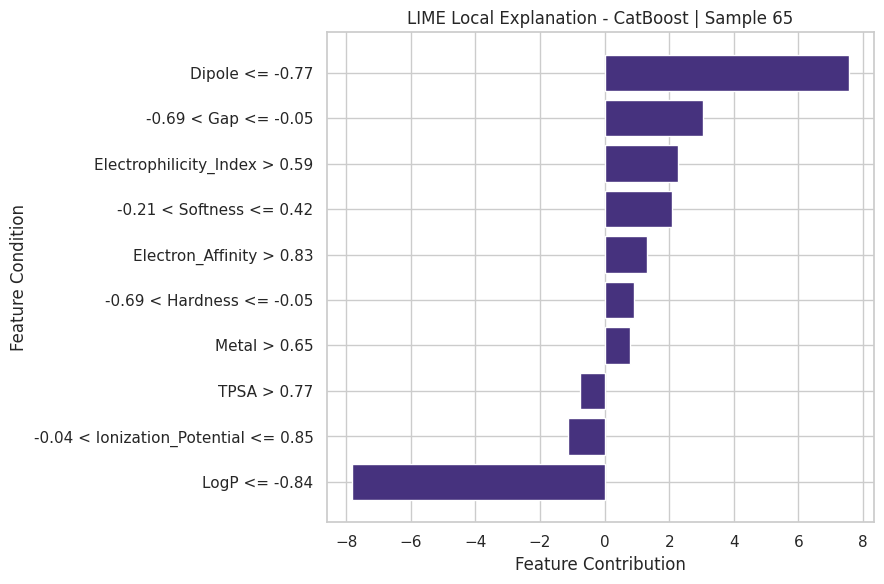


LIME Explanation for Test Sample Index: 64
Actual IC50: 73.27
Predicted IC50: 70.61604557866778


,Feature Condition,Contribution,Sample_Index,Actual_IC50,Predicted_IC50
0,Gap > 0.72,-9.841895,64,73.27,70.616046
1,Softness <= -0.73,-6.792314,64,73.27,70.616046
2,Hardness > 0.72,-4.598144,64,73.27,70.616046
3,-0.01 < LogP <= 0.83,3.510148,64,73.27,70.616046
4,-0.77 < Dipole <= 0.05,2.681353,64,73.27,70.616046
5,Electrophilicity_Index <= -0.79,-2.208011,64,73.27,70.616046
6,LUMO > 0.74,-1.264528,64,73.27,70.616046
7,Electron_Affinity <= -0.74,-1.212613,64,73.27,70.616046
8,-0.91 < Ionization_Potential <= -0.04,0.975394,64,73.27,70.616046
9,0.04 < HOMO <= 0.91,0.354808,64,73.27,70.616046


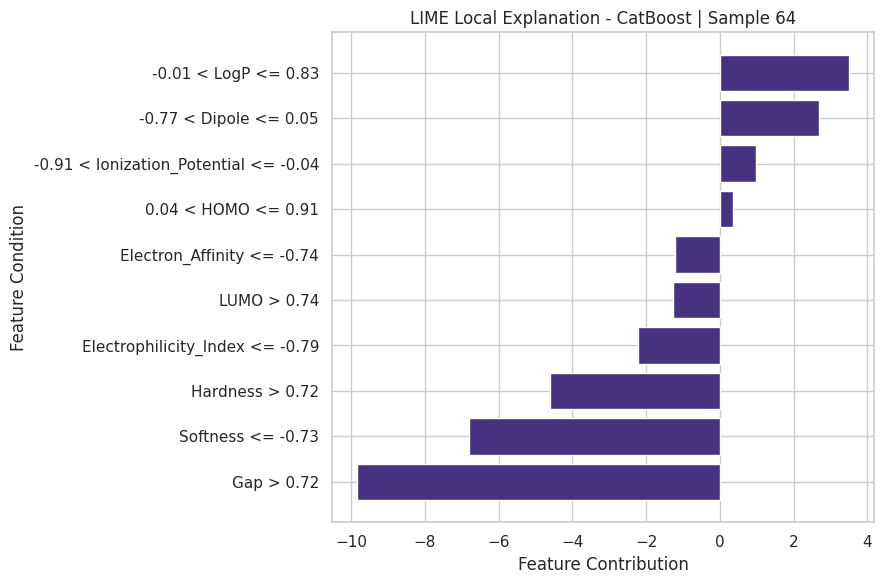


Combined LIME Explanations for 3 Random Samples:


,Feature Condition,Contribution,Sample_Index,Actual_IC50,Predicted_IC50
0,Gap > 0.72,-9.126299,30,87.31,88.380005
1,LogP > 0.83,8.213484,30,87.31,88.380005
2,Dipole <= -0.77,7.371894,30,87.31,88.380005
3,Softness <= -0.73,-6.519187,30,87.31,88.380005
4,Hardness > 0.72,-4.666209,30,87.31,88.380005
5,Ionization_Potential > 0.85,-1.631536,30,87.31,88.380005
6,HOMO <= -0.85,-1.596840,30,87.31,88.380005
7,-0.79 < Electrophilicity_Index <= -0.25,-0.898075,30,87.31,88.380005
8,-0.88 < TPSA <= 0.00,0.822772,30,87.31,88.380005
9,-0.83 < LUMO <= 0.07,0.737130,30,87.31,88.380005


In [ ]:
# ============================
# LIME Code for CatBoost - 3 Random Test Samples
# Required: trained_models["CatBoost"], X_train_scaled_df, X_test_scaled_df, y_test
# ============================

!pip install lime -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer

# LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=np.array(X_train_scaled_df),
    feature_names=X_train_scaled_df.columns.tolist(),
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

# Select 3 random test samples
np.random.seed(42)
random_sample_indices = np.random.choice(
    X_test_scaled_df.shape[0],
    size=3,
    replace=False
)

print("Random selected sample indices:", random_sample_indices)

# Store all LIME explanations
all_lime_results = []

for sample_index in random_sample_indices:

    print("\n" + "="*70)
    print(f"LIME Explanation for Test Sample Index: {sample_index}")
    print("="*70)

    # Generate LIME explanation
    lime_exp = lime_explainer.explain_instance(
        data_row=X_test_scaled_df.iloc[sample_index].values,
        predict_fn=trained_models["CatBoost"].predict,
        num_features=10
    )

    # Actual and predicted values
    actual_value = y_test.iloc[sample_index] if hasattr(y_test, "iloc") else y_test.values[sample_index]
    predicted_value = trained_models["CatBoost"].predict(
        X_test_scaled_df.iloc[[sample_index]]
    )[0]

    print("Actual IC50:", actual_value)
    print("Predicted IC50:", predicted_value)

    # Show LIME explanation in notebook
    lime_exp.show_in_notebook(show_table=True)

    # Convert explanation to dataframe
    lime_df = pd.DataFrame(
        lime_exp.as_list(),
        columns=["Feature Condition", "Contribution"]
    )

    lime_df["Sample_Index"] = sample_index
    lime_df["Actual_IC50"] = actual_value
    lime_df["Predicted_IC50"] = predicted_value

    display(lime_df)

    # Save explanation in list
    all_lime_results.append(lime_df)

    # LIME bar plot
    lime_df_sorted = lime_df.sort_values(by="Contribution", ascending=True)

    plt.figure(figsize=(9, 6))
    plt.barh(
        lime_df_sorted["Feature Condition"],
        lime_df_sorted["Contribution"]
    )

    plt.title(f"LIME Local Explanation - CatBoost | Sample {sample_index}")
    plt.xlabel("Feature Contribution")
    plt.ylabel("Feature Condition")
    plt.tight_layout()
    plt.show()

# Combine all 3 sample explanations
lime_all_samples_df = pd.concat(all_lime_results, ignore_index=True)

print("\nCombined LIME Explanations for 3 Random Samples:")
display(lime_all_samples_df)